[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/DANIFUZZY1975/estadistica-descriptiva-python/blob/main/notebooks/01_fifa_jugadores.ipynb)

# ⚽ Estadística descriptiva con 17.000 futbolistas de EA Sports FC

**Estadística Descriptiva · 1.º Grado en Ciencia de Datos · UCM** — Prof. Daniel Gómez

Cada fila es un **jugador** del videojuego, con su valoración global (`OVR`), sus seis medias
(`PAC` ritmo, `SHO` tiro, `PAS` pase, `DRI` regate, `DEF` defensa, `PHY` físico), decenas de atributos
detallados, y datos como edad, altura, posición, liga, equipo y nacionalidad.

Preguntas que vamos a responder:
- ¿Cómo es el jugador "típico"? ¿Media, mediana o moda?
- ¿Qué **liga** es mejor… y cuál es más **igualada**?
- ¿A qué **edad** alcanza un futbolista su pico?
- ¿Quién es el jugador más **anómalo** (excepcional) en cada atributo?
- ¿Por qué algunos histogramas tienen **dos jorobas**?

> 💡 Ejecuta las celdas en orden. Donde veas **🤔**, para y piensa antes de seguir.

**Plan de trabajo (3 sesiones de 2 h):**
- 🕐 Sesión 1 · Conocer los datos y describir una variable (apartados 1–6)
- 🕐 Sesión 2 · Atípicos, tipificación y comparación de grupos (7–9)
- 🕐 Sesión 3 · Dos variables: correlación y regresión (10–12)

In [1]:
# ============================================================
# 0. Librerías, estilo y funciones de apoyo
# ============================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda v: f"{v:,.4g}" if v != 0 and abs(v) < 0.01 else f"{v:,.3f}")

sns.set_theme(style="whitegrid", context="notebook")
AZUL, NARANJA, VERDE, AMARILLO = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
plt.rcParams.update({"figure.figsize": (10, 4), "axes.titleweight": "bold"})

# Los datos se leen del repositorio de GitHub, así el notebook funciona
# igual en Colab, en Jupyter local o en VS Code sin subir nada a mano.
URL_DATOS = "https://raw.githubusercontent.com/DANIFUZZY1975/estadistica-descriptiva-python/main/data/"

def cargar(nombre, **kwargs):
    """Busca el CSV en local (../data o carpeta actual); si no está, lo baja de GitHub."""
    for ruta in (os.path.join("..", "data", nombre), os.path.join("data", nombre), nombre):
        if os.path.exists(ruta):
            return pd.read_csv(ruta, **kwargs)
    return pd.read_csv(URL_DATOS + nombre, **kwargs)


def moda(x, bins="sturges"):
    """Moda:
    - variable discreta (pocos valores distintos) -> valor más repetido;
    - variable continua -> moda INTERPOLADA dentro de la clase modal del histograma:
          Mo = L + d1 / (d1 + d2) * a
      con L = extremo inferior de la clase modal, a = su amplitud,
          d1 = n_i - n_(i-1)  (diferencia con la clase de la izquierda),
          d2 = n_i - n_(i+1)  (diferencia con la clase de la derecha).
      Es el punto donde se cortan las rectas que unen, en cruz, las esquinas superiores
      de la barra modal con las de sus vecinas: si la vecina izquierda es más alta,
      la moda se desplaza a la izquierda, y al revés. Siempre queda dentro de la clase modal."""
    x = pd.Series(x).dropna()
    if x.nunique() <= 30:
        return x.mode().iloc[0]
    frec, bordes = np.histogram(x, bins=bins)
    i = frec.argmax()
    n_izq = frec[i - 1] if i > 0 else 0
    n_der = frec[i + 1] if i < len(frec) - 1 else 0
    d1, d2 = frec[i] - n_izq, frec[i] - n_der
    L, a = bordes[i], bordes[i + 1] - bordes[i]
    if d1 + d2 == 0:          # meseta: las tres barras iguales -> punto medio
        return L + a / 2
    return L + d1 / (d1 + d2) * a


def limites_tukey(x, k=1.5):
    """Vallas de Tukey: [Q1 - k·IQR , Q3 + k·IQR] (las del diagrama de caja)."""
    q1, q3 = np.nanquantile(x, [0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr


def resumen(x):
    """Todas las medidas descriptivas de una variable cuantitativa en una Serie."""
    x = pd.Series(x).dropna().astype(float)
    q1, me, q3 = x.quantile([0.25, 0.50, 0.75])
    li, ls = limites_tukey(x)
    return pd.Series({
        # --- tamaño
        "n": x.size,
        # --- medidas de posición central
        "media": x.mean(),
        "mediana": me,
        "moda": moda(x),
        "media_recortada_5%": stats.trim_mean(x, 0.05),  # quita el 5 % de CADA cola
        # --- medidas de posición no central
        "min": x.min(), "Q1": q1, "Q3": q3, "max": x.max(),
        # --- medidas de dispersión
        "rango": x.max() - x.min(),
        "IQR": q3 - q1,
        "varianza": x.var(),          # cuasivarianza (divide entre n-1)
        "desv_tipica": x.std(),       # cuasidesviación típica (n-1)
        "CV_%": 100 * x.std() / abs(x.mean()) if x.mean() != 0 else np.nan,
        "MAD": stats.median_abs_deviation(x),  # mediana de |x - mediana|
        # --- medidas de forma
        "asimetria_Fisher": x.skew(),
        "asimetria_Pearson": 3 * (x.mean() - me) / x.std(),
        "curtosis_exceso": x.kurt(),  # 0 = como la normal
        # --- anómalos
        "n_atipicos_Tukey": int(((x < li) | (x > ls)).sum()),
    })


def histograma_con_centros(x, titulo="", bins="sturges", ax=None, color=AZUL):
    """Histograma + KDE con media, mediana y moda marcadas."""
    x = pd.Series(x).dropna()
    ax = ax or plt.gca()
    sns.histplot(x, bins=bins, kde=True, color=color, alpha=0.35, ax=ax)
    for valor, etiqueta, estilo in [(x.mean(), "media", "-"),
                                    (x.median(), "mediana", "--"),
                                    (moda(x, bins=bins), "moda", ":")]:
        ax.axvline(valor, color="#333333", ls=estilo, lw=2,
                   label=f"{etiqueta} = {valor:,.2f}")
    ax.set_title(titulo or x.name)
    ax.legend(frameon=False)
    return ax


# ============================================================
# Regresión: lineal, potencial y exponencial
# ============================================================
def r2(y_obs, y_pred):
    """Coeficiente de determinación: 1 - SCresidual / SCtotal."""
    y_obs, y_pred = np.asarray(y_obs, float), np.asarray(y_pred, float)
    return 1 - np.sum((y_obs - y_pred) ** 2) / np.sum((y_obs - y_obs.mean()) ** 2)


def recta_minimos_cuadrados(x, y):
    """Recta de regresión de y sobre x:  y = a + b·x,
    b = S_xy / S_x^2   y   a = media(y) - b·media(x)."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    sxy = np.mean((x - x.mean()) * (y - y.mean()))
    sx2 = np.mean((x - x.mean()) ** 2)
    b = sxy / sx2
    a = y.mean() - b * x.mean()
    return a, b


def regresiones(x, y):
    """Ajusta los tres modelos por mínimos cuadrados.
    - Lineal:      y = a + b·x
    - Potencial:   y = a·x^b      ->  ln y = ln a + b·ln x   (exige x > 0 e y > 0)
    - Exponencial: y = a·e^(b·x)  ->  ln y = ln a + b·x      (exige y > 0)
    Devuelve (tabla, modelos), donde modelos[nombre] es una función que predice y."""
    datos = pd.DataFrame({"x": x, "y": y}).dropna()
    x, y = datos["x"].to_numpy(float), datos["y"].to_numpy(float)
    filas, modelos = [], {}

    a, b = recta_minimos_cuadrados(x, y)
    modelos["lineal"] = lambda t, a=a, b=b: a + b * np.asarray(t, float)
    filas.append({"modelo": "lineal", "ecuación": f"y = {a:,.4g} + {b:,.4g}·x", "a": a, "b": b,
                  "R2 (escala del ajuste)": r2(y, modelos["lineal"](x)),
                  "R2 (escala original)": r2(y, modelos["lineal"](x))})

    if (x > 0).all() and (y > 0).all():
        A, b = recta_minimos_cuadrados(np.log(x), np.log(y))
        a = np.exp(A)
        modelos["potencial"] = lambda t, a=a, b=b: a * np.asarray(t, float) ** b
        filas.append({"modelo": "potencial", "ecuación": f"y = {a:,.4g}·x^{b:,.4g}", "a": a, "b": b,
                      "R2 (escala del ajuste)": r2(np.log(y), A + b * np.log(x)),
                      "R2 (escala original)": r2(y, modelos["potencial"](x))})
    else:
        filas.append({"modelo": "potencial", "ecuación": "no aplicable: necesita x > 0 e y > 0"})

    if (y > 0).all():
        A, b = recta_minimos_cuadrados(x, np.log(y))
        a = np.exp(A)
        modelos["exponencial"] = lambda t, a=a, b=b: a * np.exp(b * np.asarray(t, float))
        filas.append({"modelo": "exponencial", "ecuación": f"y = {a:,.4g}·e^({b:,.4g}·x)", "a": a, "b": b,
                      "R2 (escala del ajuste)": r2(np.log(y), A + b * x),
                      "R2 (escala original)": r2(y, modelos["exponencial"](x))})
    else:
        filas.append({"modelo": "exponencial", "ecuación": "no aplicable: necesita y > 0"})

    return pd.DataFrame(filas).set_index("modelo"), modelos


COLOR_MODELO = {"lineal": AZUL, "potencial": NARANJA, "exponencial": VERDE}


def dibujar_regresiones(x, y, modelos, ax=None, n_puntos=3000, xlabel=None, ylabel=None, titulo=""):
    """Nube de puntos + las curvas ajustadas (si hay muchos puntos, se dibuja una muestra)."""
    datos = pd.DataFrame({"x": x, "y": y}).dropna()
    muestra = datos.sample(min(n_puntos, len(datos)), random_state=1)
    ax = ax or plt.gca()
    ax.scatter(muestra["x"], muestra["y"], s=10, alpha=0.3, color="#9aa0a6")
    xs = np.linspace(datos["x"].min(), datos["x"].max(), 300)
    for nombre, f in modelos.items():
        ax.plot(xs, f(xs), lw=2.5, color=COLOR_MODELO[nombre], label=nombre)
    ax.set_xlabel(xlabel or getattr(x, "name", "x")); ax.set_ylabel(ylabel or getattr(y, "name", "y"))
    ax.set_title(titulo); ax.legend(frameon=False)
    return ax

---
# 🕐 Sesión 1 de 3 · Conocer los datos y describir una variable
**Objetivos:** limpiar el dataset, descubrir problemas de agrupación, tablas de frecuencias, medidas de posición, dispersión y forma.  
**Apartados:** 1 a 6 · **Duración orientativa:** 2 horas

## 1. Carga y limpieza
El CSV usa `;` como separador. Trae columnas "basura" (`Unnamed: ...`) que vienen de índices guardados al exportar
y de las celdas vacías tras altura y peso.

In [2]:
df = cargar("all_players_dani.csv", sep=";")
print("Dimensiones originales:", df.shape)
df = df.loc[:, ~df.columns.str.startswith("Unnamed")]   # fuera TODAS las columnas Unnamed de una vez
df = df.rename(columns={"Height": "Height_cm", "Weight": "Weight_kg"})
print("Dimensiones tras limpiar:", df.shape)
df.head()

Dimensiones originales: (17737, 54)
Dimensiones tras limpiar: (17737, 50)


,Rank,Name,OVR,PAC,SHO,PAS,DRI,DEF,PHY,Acceleration,Sprint Speed,Positioning,Finishing,Shot Power,Long Shots,Volleys,Penalties,Vision,Crossing,Free Kick Accuracy,Short Passing,Long Passing,Curve,Dribbling,Agility,Balance,Reactions,Ball Control,Composure,Interceptions,Heading Accuracy,Def Awareness,Standing Tackle,Sliding Tackle,Jumping,Stamina,Strength,Aggression,Position,Weak foot,Skill moves,Preferred foot,Height_cm,Weight_kg,Alternative positions,Age,Nation,League,Team,play style
0,1,Kylian Mbappé,91,97,90,80,92,36,78,97,97,93,94,90,83,84,84,83,78,69,86,71,80,93,93,82,93,92,88,38,73,26,34,32,88,88,77,64,ST,4,5,Right,182,75,LW,25,France,LALIGA EA SPORTS,Real Madrid,"Quick Step+, Acrobatic, Finesse Shot, Flair, R..."
1,2,Rodri,91,66,80,86,84,87,85,65,66,76,74,92,89,71,62,84,76,64,93,91,86,84,66,67,93,90,94,84,81,92,87,82,83,91,83,85,CDM,4,3,Right,191,82,CM,28,Spain,Premier League,Manchester City,"Tiki Taka+, Aerial, Bruiser, Long Ball Pass, P..."
2,4,Erling Haaland,91,88,92,70,81,45,88,80,94,96,96,94,83,90,90,74,58,62,77,66,77,79,77,69,94,83,87,43,83,38,47,29,92,76,93,88,ST,3,3,Left,195,94,NaN,24,Norway,Premier League,Manchester City,"Acrobatic+, Bruiser, Power Header, Power Shot,..."
3,5,Jude Bellingham,90,80,87,83,88,78,83,81,80,91,90,85,86,77,74,90,66,68,89,89,73,89,82,79,91,89,87,82,75,77,79,77,84,93,77,85,CAM,4,4,Right,186,75,CM,21,England,LALIGA EA SPORTS,Real Madrid,"Relentless+, Flair, Intercept, Slide Tackle, T..."
4,7,Vini Jr.,90,95,84,81,91,29,69,95,95,87,89,81,83,73,71,85,81,62,83,77,79,93,94,84,86,90,83,26,50,32,25,18,74,84,65,58,LW,4,5,Right,176,73,"ST, LM",24,Brazil,LALIGA EA SPORTS,Real Madrid,"Quick Step+, Chip Shot, Finesse Shot, First To..."


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17737 entries, 0 to 17736
Data columns (total 50 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   Rank                   17737 non-null  int64
 1   Name                   17737 non-null  str  
 2   OVR                    17737 non-null  int64
 3   PAC                    17737 non-null  int64
 4   SHO                    17737 non-null  int64
 5   PAS                    17737 non-null  int64
 6   DRI                    17737 non-null  int64
 7   DEF                    17737 non-null  int64
 8   PHY                    17737 non-null  int64
 9   Acceleration           17737 non-null  int64
 10  Sprint Speed           17737 non-null  int64
 11  Positioning            17737 non-null  int64
 12  Finishing              17737 non-null  int64
 13  Shot Power             17737 non-null  int64
 14  Long Shots             17737 non-null  int64
 15  Volleys                17737 non-null  int64
 1

In [4]:
print("Valores faltantes por columna (solo las que tienen):")
print(df.isna().sum()[lambda s: s > 0])
print("\n¿Jugadores duplicados (mismo nombre, equipo y edad)?", df.duplicated(["Name", "Team", "Age"]).sum())

Valores faltantes por columna (solo las que tienen):
Alternative positions    7959
play style               9496
dtype: int64

¿Jugadores duplicados (mismo nombre, equipo y edad)? 1


### 🕵️ Primer análisis: ¿cuántos jugadores tiene cada equipo?
Antes de comparar equipos, conviene saber **cuántos datos tiene cada grupo**. Creamos una variable nueva,
`plantilla` = número de jugadores por equipo, y la describimos como cualquier otra variable cuantitativa.
(Ojo: ahora la unidad estadística ya no es el jugador, es el **equipo**.)

In [5]:
plantilla = df["Team"].value_counts().rename("plantilla")
print("Número de equipos:", plantilla.size)
resumen(plantilla).round(2)

Número de equipos: 685


n                    685.000
media                 25.890
mediana               25.000
moda                  24.770
media_recortada_5%    25.230
min                    5.000
Q1                    22.000
Q3                    28.000
max                   68.000
rango                 63.000
IQR                    6.000
varianza              65.790
desv_tipica            8.110
CV_%                  31.330
MAD                    3.000
asimetria_Fisher       1.730
asimetria_Pearson      0.330
curtosis_exceso        5.240
n_atipicos_Tukey      69.000
dtype: float64

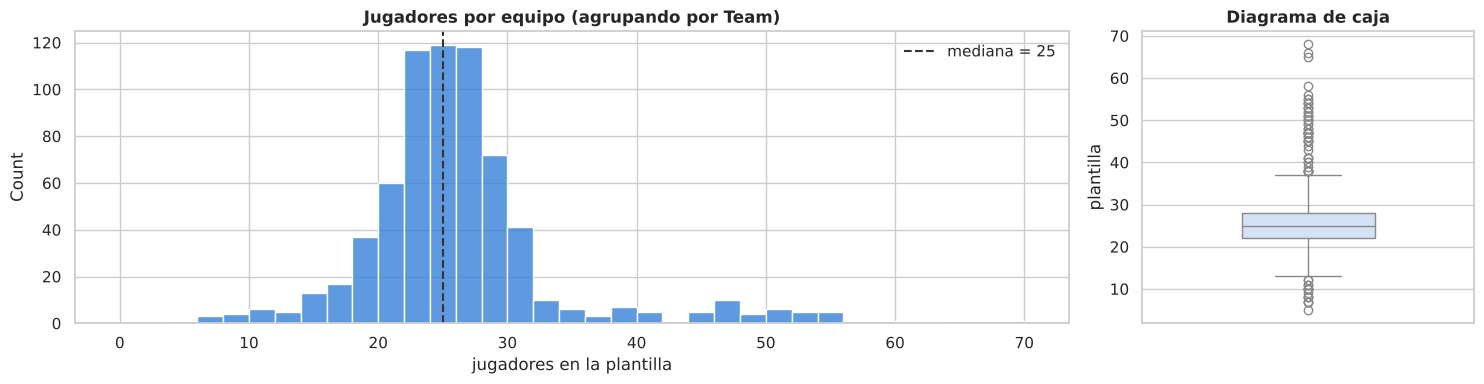

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4), gridspec_kw={"width_ratios": [3, 1]})
sns.histplot(plantilla, bins=range(0, 72, 2), color=AZUL, ax=axes[0])
axes[0].axvline(plantilla.median(), color="#333333", ls="--", label=f"mediana = {plantilla.median():.0f}")
axes[0].set_title("Jugadores por equipo (agrupando por Team)"); axes[0].set_xlabel("jugadores en la plantilla")
axes[0].legend(frameon=False)
sns.boxplot(y=plantilla, color="#cde2fb", width=0.4, ax=axes[1]); axes[1].set_title("Diagrama de caja")
plt.tight_layout(); plt.show()

🤔 La mayoría de equipos tiene entre 22 y 28 jugadores (lo normal en una plantilla)… pero hay una **segunda joroba** entre 45 y 68,
y la caja marca muchos **atípicos**. ¿Quiénes son?

In [7]:
li, ls = limites_tukey(plantilla)
grandes = plantilla[plantilla > ls]
print(f"Vallas de Tukey: [{li:.1f}, {ls:.1f}] -> {len(grandes)} equipos atípicos por arriba")
grandes.head(15).to_frame()

Vallas de Tukey: [13.0, 37.0] -> 53 equipos atípicos por arriba


,plantilla
Team,
Everton,68
Liverpool,66
Chelsea,65
VfL Wolfsburg,58
1. FC Köln,56
OL,55
Racing Club,55
SC Freiburg,54
Brighton,54


Everton 68, Liverpool 66, Chelsea 65… ¿Tienen el triple de jugadores que el resto? Abramos uno:

In [8]:
df[df["Team"] == "Liverpool"].groupby("League").agg(n=("Name", "size"), altura_mediana=("Height_cm", "median"))

,n,altura_mediana
League,,
Barclays WSL,21,170.000
Libertadores,12,179.000
Premier League,33,185.000


Bajo el nombre "Liverpool" hay **tres equipos distintos**: el masculino (Premier League), el **femenino** (Barclays WSL)
y el **Liverpool de Montevideo** (Uruguay, Copa Libertadores). Los atípicos no eran equipos enormes: eran **varios equipos con el mismo nombre**.
El análisis descriptivo de una variable aparentemente aburrida nos ha descubierto un problema en cómo agrupábamos.

**Solución:** identificar cada equipo por *nombre + liga* y repetir la descripción.

In [9]:
df["equipo"] = df["Team"] + " (" + df["League"] + ")"
plantilla2 = df["equipo"].value_counts().rename("plantilla")
pd.DataFrame({"por Team": resumen(plantilla), "por equipo + liga": resumen(plantilla2)}).round(2)

,por Team,por equipo + liga
n,685.000,735.000
media,25.890,24.130
mediana,25.000,24.000
moda,24.770,24.450
media_recortada_5%,25.230,24.260
min,5.000,5.000
Q1,22.000,22.000
Q3,28.000,27.000
max,68.000,55.000
rango,63.000,50.000


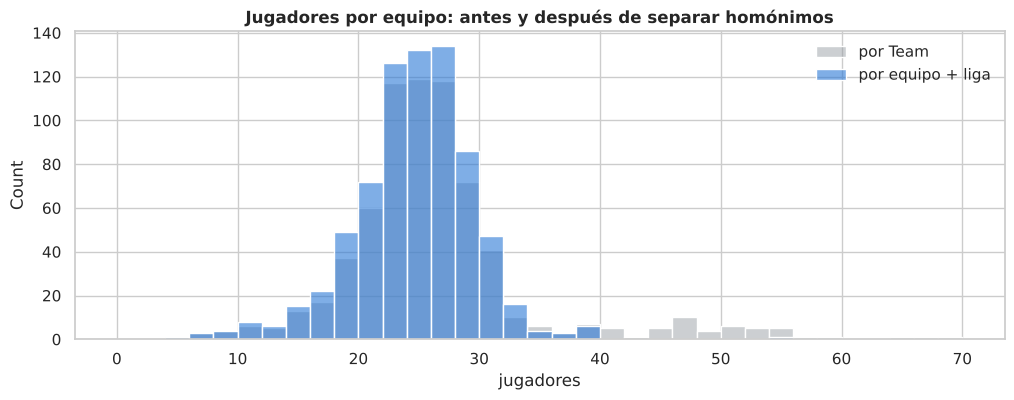

Atípicos ahora: 41 (antes: 69)


,plantilla
equipo,
Racing Club (Sudamericana),55
Daejeon (K League 1),38
Daegu FC (K League 1),38
Incheon United (K League 1),38
Jeonbuk Hyundai (K League 1),38
Suwon FC (K League 1),38
Jeju United (K League 1),38
Pohang Steelers (K League 1),37


In [10]:
fig, ax = plt.subplots(figsize=(12, 4))
sns.histplot(plantilla, bins=range(0, 72, 2), color="#9aa0a6", alpha=0.5, label="por Team", ax=ax)
sns.histplot(plantilla2, bins=range(0, 72, 2), color=AZUL, alpha=0.6, label="por equipo + liga", ax=ax)
ax.set_title("Jugadores por equipo: antes y después de separar homónimos"); ax.set_xlabel("jugadores")
ax.legend(frameon=False); plt.show()

li2, ls2 = limites_tukey(plantilla2)
print(f"Atípicos ahora: {((plantilla2 < li2) | (plantilla2 > ls2)).sum()} (antes: {((plantilla < li) | (plantilla > ls)).sum()})")
plantilla2.head(8).to_frame()

🤔 La segunda joroba ha desaparecido y la desviación típica ha bajado mucho. Pero **Racing Club** sigue con 55 jugadores en la
Sudamericana… ¿Cuántos "Racing Club" conoces en Sudamérica? Y los equipos coreanos (K League) tienen 38: ¿error o plantillas más largas?

El dataset incluye **ligas femeninas**. ¿Cómo las encontramos sin leer los 56 nombres? Con estadística:
la **mediana de altura** por liga separa claramente dos grupos.

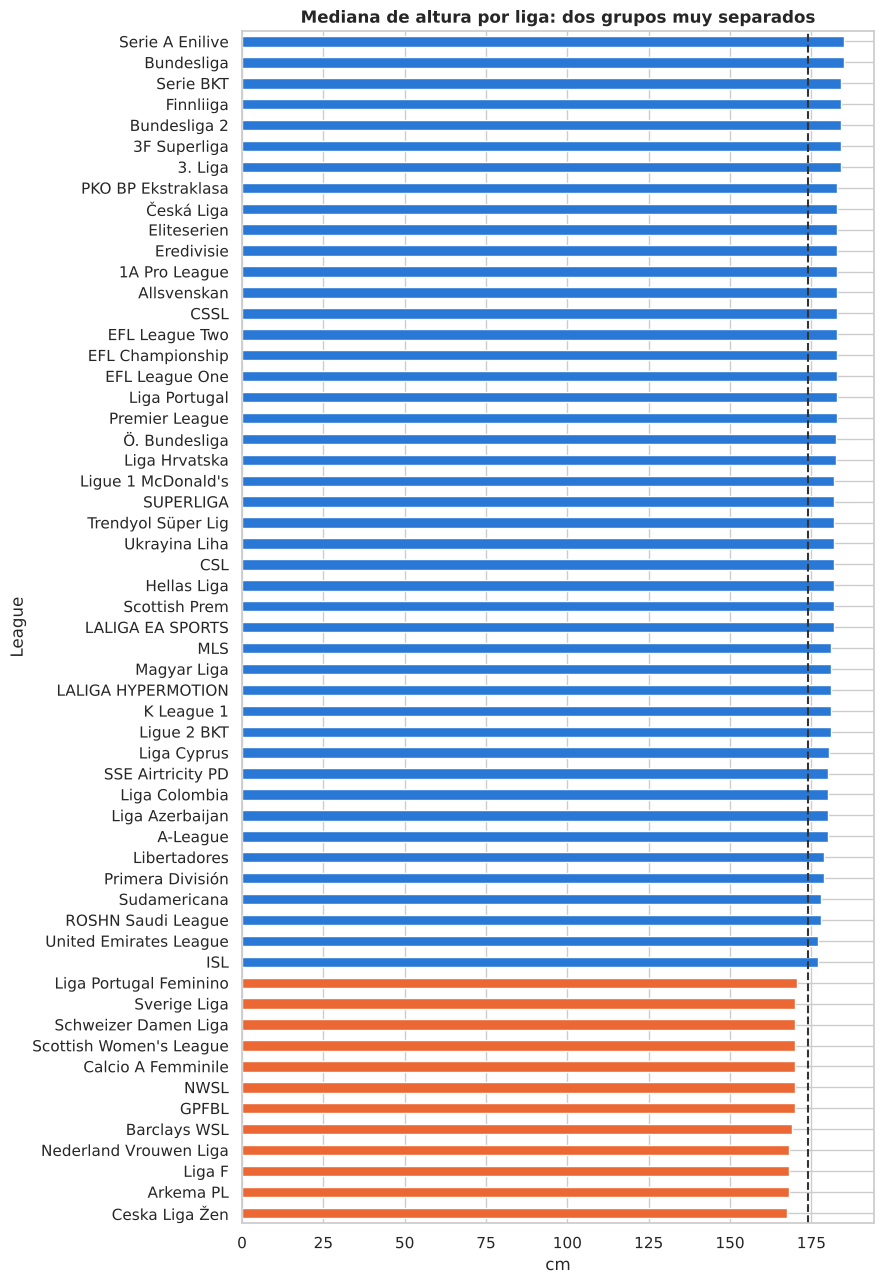

In [11]:
alt_liga = df.groupby("League")["Height_cm"].median().sort_values()
ax = alt_liga.plot.barh(figsize=(9, 13), color=np.where(alt_liga < 174, NARANJA, AZUL))
ax.axvline(174, color="#333333", ls="--")
ax.set_title("Mediana de altura por liga: dos grupos muy separados"); ax.set_xlabel("cm")
plt.tight_layout(); plt.show()

In [12]:
ligas_femeninas = alt_liga[alt_liga < 174].index.tolist()
print("Ligas femeninas:", ligas_femeninas)
df["sexo"] = np.where(df["League"].isin(ligas_femeninas), "Femenino", "Masculino")
df.groupby("sexo")[["OVR", "Height_cm", "Weight_kg", "Age"]].agg(["size", "mean", "median"]).round(1).T

Ligas femeninas: ['Ceska Liga Žen', 'Arkema PL', 'Liga F', 'Nederland Vrouwen Liga', 'Barclays WSL', 'GPFBL', 'NWSL', 'Calcio A Femminile', "Scottish Women's League", 'Schweizer Damen Liga', 'Sverige Liga', 'Liga Portugal Feminino']


sexo              Femenino  Masculino
OVR       size   1,576.000 16,161.000
          mean      73.200     66.200
          median    73.000     66.000
Height_cm size   1,576.000 16,161.000
          mean     168.800    181.900
          median   169.000    182.000
Weight_kg size   1,576.000 16,161.000
          mean      60.300     75.300
          median    60.000     75.000
Age       size   1,576.000 16,161.000
          mean      25.300     25.800
          median    25.000     25.000

🤔 **¿Por qué las jugadoras tienen un OVR medio 7 puntos mayor?** Mirad qué ligas hay de cada grupo: de hombres están también
la 2.ª, 3.ª y 4.ª división inglesa, la 3. Liga alemana…; de mujeres, solo las primeras divisiones. **Los grupos no se han
seleccionado igual**, así que comparar sus medias no compara lo mismo. Además, el juego calibra el `OVR` dentro de cada fútbol.

Altura y peso sí son medidas físicas comparables, y eso afectará a los atípicos (apartado 7).

### Tipos de variables
| Variable | Tipo |
|---|---|
| `Name`, `Team`, `Nation`, `League`, `Position`, `Preferred foot` | cualitativas nominales |
| `Weak foot`, `Skill moves` (1 a 5 estrellas) | cualitativas **ordinales** (o cuantitativas discretas) |
| `OVR`, `PAC`…`PHY`, atributos | cuantitativas discretas (enteros 0–99) que tratamos como continuas |
| `Age` | cuantitativa discreta |
| `Height_cm`, `Weight_kg` | cuantitativas continuas (redondeadas) |

🤔 *`Rank` es un número… ¿tiene sentido calcular su media?*

In [13]:
seis = ["PAC", "SHO", "PAS", "DRI", "DEF", "PHY"]
atributos = df.loc[:, "Acceleration":"Aggression"].columns.tolist()
cuantitativas = ["OVR"] + seis + ["Age", "Height_cm", "Weight_kg"]
cualitativas = ["Position", "Preferred foot", "League", "Nation", "Team"]

## 2. Variables cualitativas: tablas de frecuencias

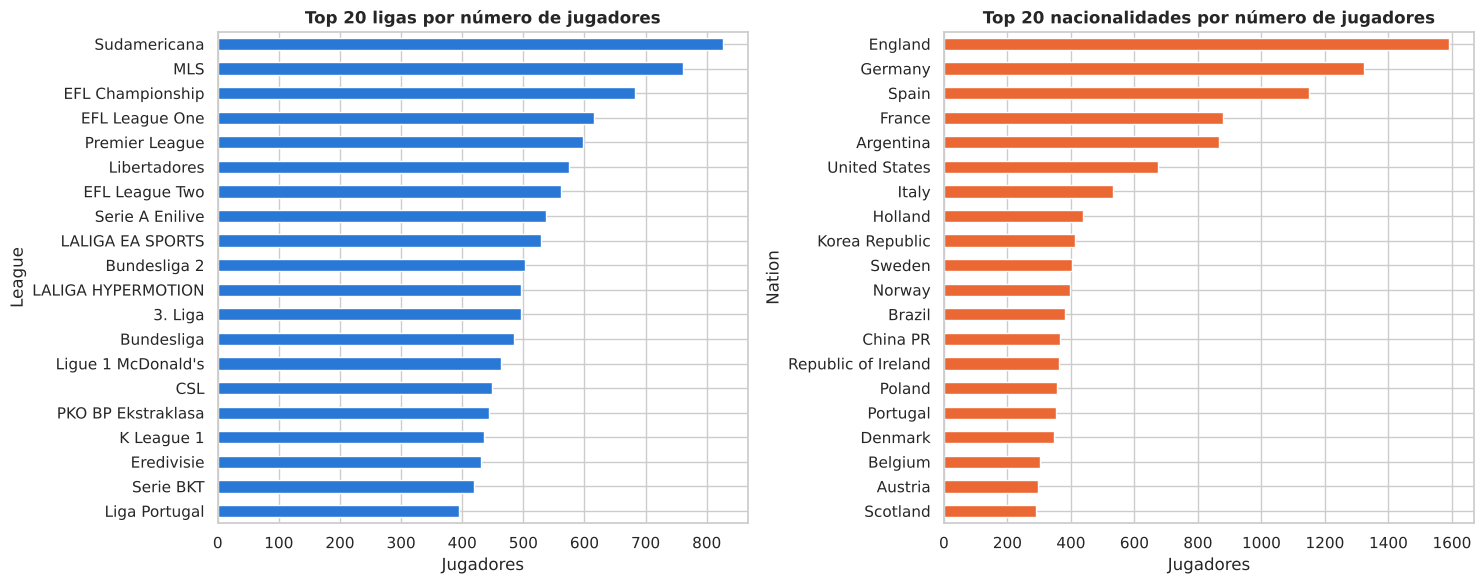

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
df["League"].value_counts().head(20).sort_values().plot.barh(ax=axes[0], color=AZUL)
axes[0].set_title("Top 20 ligas por número de jugadores"); axes[0].set_xlabel("Jugadores")
df["Nation"].value_counts().head(20).sort_values().plot.barh(ax=axes[1], color=NARANJA)
axes[1].set_title("Top 20 nacionalidades por número de jugadores"); axes[1].set_xlabel("Jugadores")
plt.tight_layout(); plt.show()

### Variable nominal: `Position`

In [15]:
tabla_pos = df["Position"].value_counts().to_frame("n_i")
tabla_pos["f_i_%"] = 100 * tabla_pos["n_i"] / len(df)
tabla_pos

,n_i,f_i_%
Position,,
CB,3185,17.957
ST,2425,13.672
CM,2139,12.060
GK,1999,11.270
CDM,1447,8.158
RB,1404,7.916
LB,1333,7.515
LM,1035,5.835
CAM,1024,5.773


### Variable ordinal: `Skill moves` — aquí las frecuencias **acumuladas** sí tienen sentido

In [16]:
tabla_sm = df["Skill moves"].value_counts().sort_index().to_frame("n_i")
tabla_sm["f_i"] = tabla_sm["n_i"] / tabla_sm["n_i"].sum()
tabla_sm["N_i"] = tabla_sm["n_i"].cumsum()
tabla_sm["F_i"] = tabla_sm["f_i"].cumsum()
tabla_sm

,n_i,f_i,N_i,F_i
Skill moves,,,,
1,1999,0.113,1999,0.113
2,7871,0.444,9870,0.556
3,6531,0.368,16401,0.925
4,1282,0.072,17683,0.997
5,54,0.003044,17737,1.000


🤔 ¿Qué porcentaje de jugadores tiene **3 estrellas o menos** en filigranas? ¿Cuál es la **mediana** de `Skill moves`?
(pista: el primer valor con `F_i ≥ 0.5`)

In [17]:
zurdos = 100 * (df["Preferred foot"] == "Left").mean()
print(f"Zurdos: {zurdos:.1f} %   (en la población general se estima un ~10 %)")

Zurdos: 23.3 %   (en la población general se estima un ~10 %)


## 3. Medidas de posición de la valoración global `OVR`

In [18]:
x = df["OVR"]
print(f"Media                 : {x.mean():.2f}")
print(f"Mediana               : {x.median():.2f}")
print(f"Moda                  : {x.mode().tolist()}")
print(f"Media recortada al 5% : {stats.trim_mean(x, 0.05):.2f}   (quita el 5% de cada cola = 10% de los datos)")
print("Cuartiles             :", x.quantile([.25, .5, .75]).tolist())
print("Deciles               :", x.quantile(np.arange(.1, 1, .1)).round(1).tolist())
print(f"Para estar en el top 1 % necesitas OVR ≥ {x.quantile(.99):.0f}")

Media                 : 66.80
Mediana               : 67.00
Moda                  : [66]
Media recortada al 5% : 66.76   (quita el 5% de cada cola = 10% de los datos)
Cuartiles             : [62.0, 67.0, 71.0]
Deciles               : [58.0, 61.0, 63.0, 65.0, 67.0, 68.0, 70.0, 72.0, 76.0]
Para estar en el top 1 % necesitas OVR ≥ 84


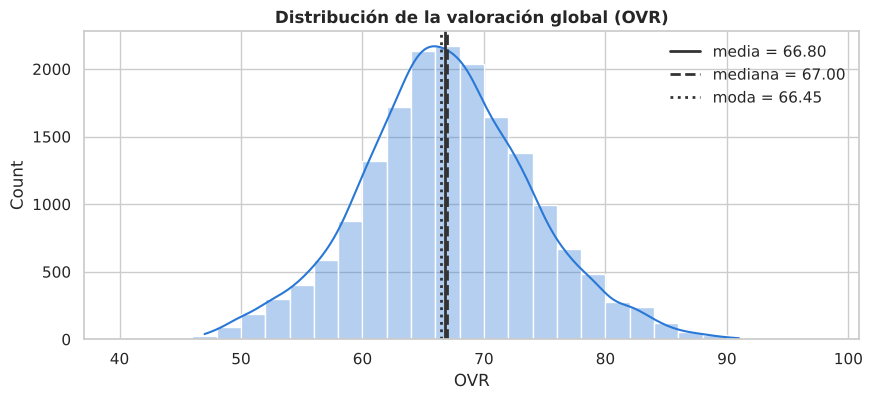

In [19]:
histograma_con_centros(df["OVR"], "Distribución de la valoración global (OVR)", bins=range(40, 100, 2))
plt.xlabel("OVR"); plt.show()

### ¿Cuántas barras pongo en el histograma? El número de clases cambia la historia

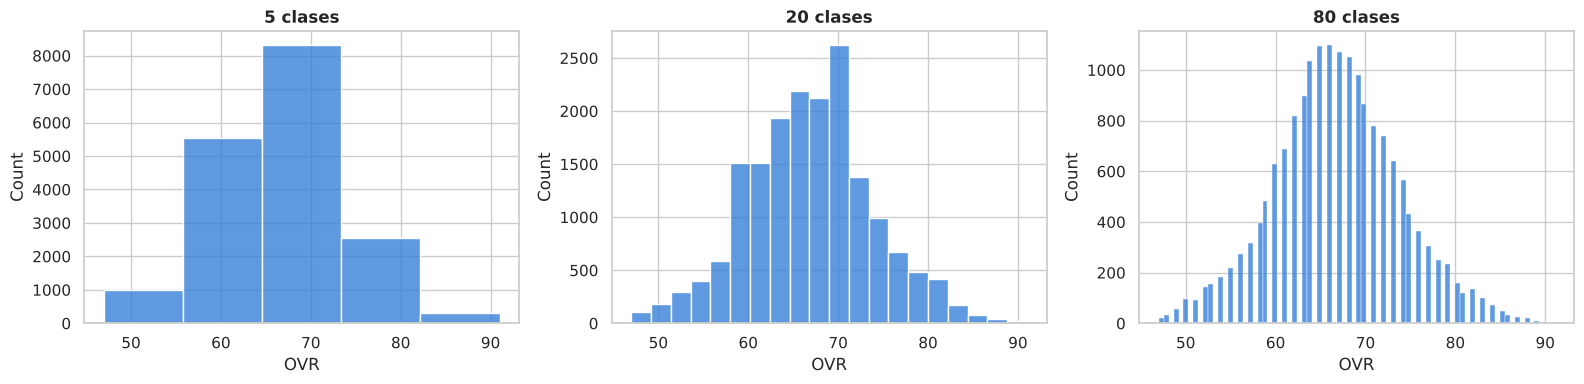

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, b in zip(axes, [5, 20, 80]):
    sns.histplot(df["OVR"], bins=b, ax=ax, color=AZUL)
    ax.set_title(f"{b} clases")
plt.tight_layout(); plt.show()

🤔 Con 5 clases no se ve nada; con 80 aparecen "huecos" porque OVR solo toma valores enteros. Reglas como
**Sturges** dan un punto de partida:
$$k \approx 1 + 3{,}322\,\log_{10} n \;=\; 1 + \log_2 n$$
(son la misma fórmula: $\log_2 n = \log_{10} n / \log_{10} 2 \approx 3{,}322\,\log_{10} n$). Aquí $1 + 3{,}322\,\log_{10}(17737) \approx 15$ clases.

La **densidad estimada (KDE)** es la versión "suavizada" del histograma:

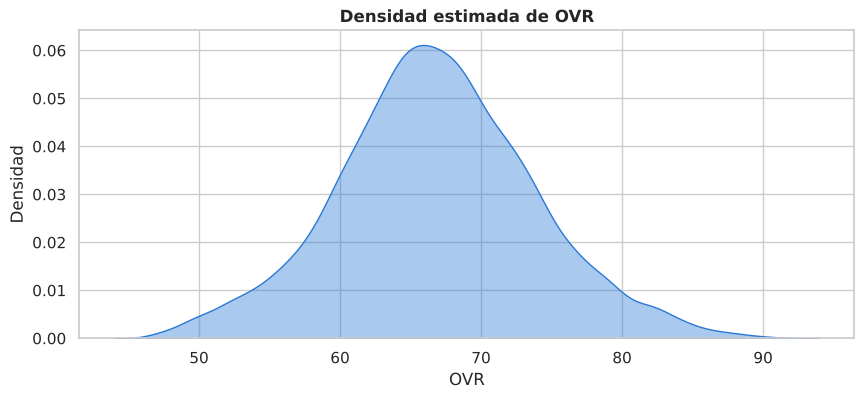

In [21]:
sns.kdeplot(data=df, x="OVR", fill=True, alpha=0.4, color=AZUL)
plt.title("Densidad estimada de OVR"); plt.ylabel("Densidad"); plt.show()

## 4. Medidas de dispersión

In [22]:
x = df["OVR"]
print(f"Rango        : {x.max() - x.min()}   ({x.min()} a {x.max()})")
print(f"IQR (rango intercuartílico): {x.quantile(.75) - x.quantile(.25)}")
print(f"Varianza     : pandas (n-1) = {x.var():.3f} | numpy (n) = {np.var(x):.3f}")
print(f"Desv. típica : pandas (n-1) = {x.std():.3f} | numpy (n) = {np.std(x):.3f}")
print(f"CV           : {100 * x.std() / x.mean():.1f} %")
print(f"MAD          : {stats.median_abs_deviation(x):.2f}")

Rango        : 44   (47 a 91)
IQR (rango intercuartílico): 9.0
Varianza     : pandas (n-1) = 49.435 | numpy (n) = 49.432
Desv. típica : pandas (n-1) = 7.031 | numpy (n) = 7.031
CV           : 10.5 %
MAD          : 4.00


### ¿Qué varía más entre jugadores: la edad, la altura o el peso?
Están en unidades distintas (años, cm, kg): comparar desviaciones típicas no tiene sentido → **coeficiente de variación**.

In [23]:
cv = pd.DataFrame({
    "media": df[["Age", "Height_cm", "Weight_kg", "OVR"]].mean(),
    "desv_tipica": df[["Age", "Height_cm", "Weight_kg", "OVR"]].std(),
})
cv["CV_%"] = 100 * cv["desv_tipica"] / cv["media"]
cv.sort_values("CV_%")

,media,desv_tipica,CV_%
Height_cm,180.707,7.733,4.279
OVR,66.796,7.031,10.526
Weight_kg,73.951,8.024,10.851
Age,25.744,4.640,18.024


## 5. Tabla resumen de las variables cuantitativas
Una función `resumen()` (definida arriba) aplicada a todas las columnas con `.apply()`.

In [24]:
tabla = df[cuantitativas].apply(resumen).T
(tabla.style.format("{:,.2f}")
     .background_gradient(subset=["asimetria_Fisher"], cmap="RdBu_r", vmin=-1.5, vmax=1.5)
     .background_gradient(subset=["CV_%"], cmap="Oranges"))

,n,media,mediana,moda,media_recortada_5%,min,Q1,Q3,max,rango,IQR,varianza,desv_tipica,CV_%,MAD,asimetria_Fisher,asimetria_Pearson,curtosis_exceso,n_atipicos_Tukey
OVR,"17,737.00",66.80,67.00,64.68,66.76,47.00,62.00,71.00,91.00,44.00,9.00,49.43,7.03,10.53,4.00,0.10,-0.09,0.13,200.00
PAC,"17,737.00",68.24,69.00,66.29,68.56,29.00,62.00,75.00,97.00,68.00,13.00,112.10,10.59,15.52,7.00,-0.48,-0.22,0.52,346.00
SHO,"17,737.00",54.85,57.00,59.16,55.13,20.00,46.00,65.00,93.00,73.00,19.00,192.06,13.86,25.27,9.00,-0.42,-0.47,-0.57,0.00
PAS,"17,737.00",59.15,60.00,62.08,59.26,25.00,53.00,66.00,94.00,69.00,13.00,96.56,9.83,16.61,6.00,-0.17,-0.26,0.03,148.00
DRI,"17,737.00",64.21,65.00,65.68,64.45,29.00,59.00,70.00,92.00,63.00,11.00,87.59,9.36,14.58,6.00,-0.44,-0.25,0.51,479.00
DEF,"17,737.00",51.22,55.00,62.98,51.41,15.00,37.00,64.00,91.00,76.00,27.00,271.52,16.48,32.17,12.00,-0.29,-0.69,-1.03,0.00
PHY,"17,737.00",65.42,66.00,70.79,65.69,32.00,59.00,72.00,91.00,59.00,13.00,89.65,9.47,14.47,6.00,-0.42,-0.18,-0.10,107.00
Age,"17,737.00",25.74,25.00,24.00,25.60,17.00,22.00,29.00,44.00,27.00,7.00,21.53,4.64,18.02,3.00,0.43,0.48,-0.39,37.00
Height_cm,"17,737.00",180.71,181.00,179.16,180.85,149.00,175.00,186.00,206.00,57.00,11.00,59.80,7.73,4.28,5.00,-0.26,-0.11,-0.09,75.00
Weight_kg,"17,737.00",73.95,74.00,76.91,74.01,45.00,69.00,79.00,105.00,60.00,10.00,64.39,8.02,10.85,5.00,-0.13,-0.02,0.10,193.00


## 6. Medidas de forma: ¿por qué hay histogramas con dos jorobas?

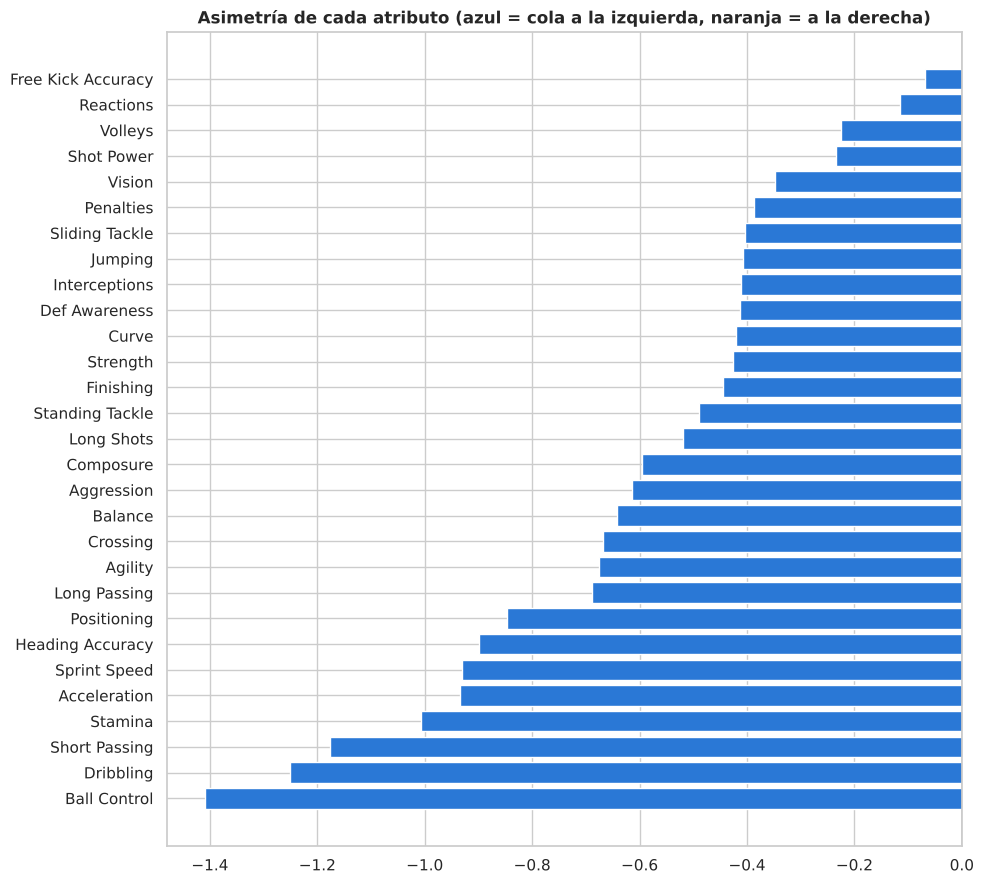

In [25]:
forma = pd.DataFrame({"asimetria": df[atributos].skew(), "curtosis": df[atributos].kurt()}).sort_values("asimetria")
fig, ax = plt.subplots(figsize=(10, 9))
colores = np.where(forma["asimetria"] < 0, AZUL, NARANJA)
ax.barh(forma.index, forma["asimetria"], color=colores)
ax.axvline(0, color="#333333", lw=1)
ax.set_title("Asimetría de cada atributo (azul = cola a la izquierda, naranja = a la derecha)")
plt.tight_layout(); plt.show()

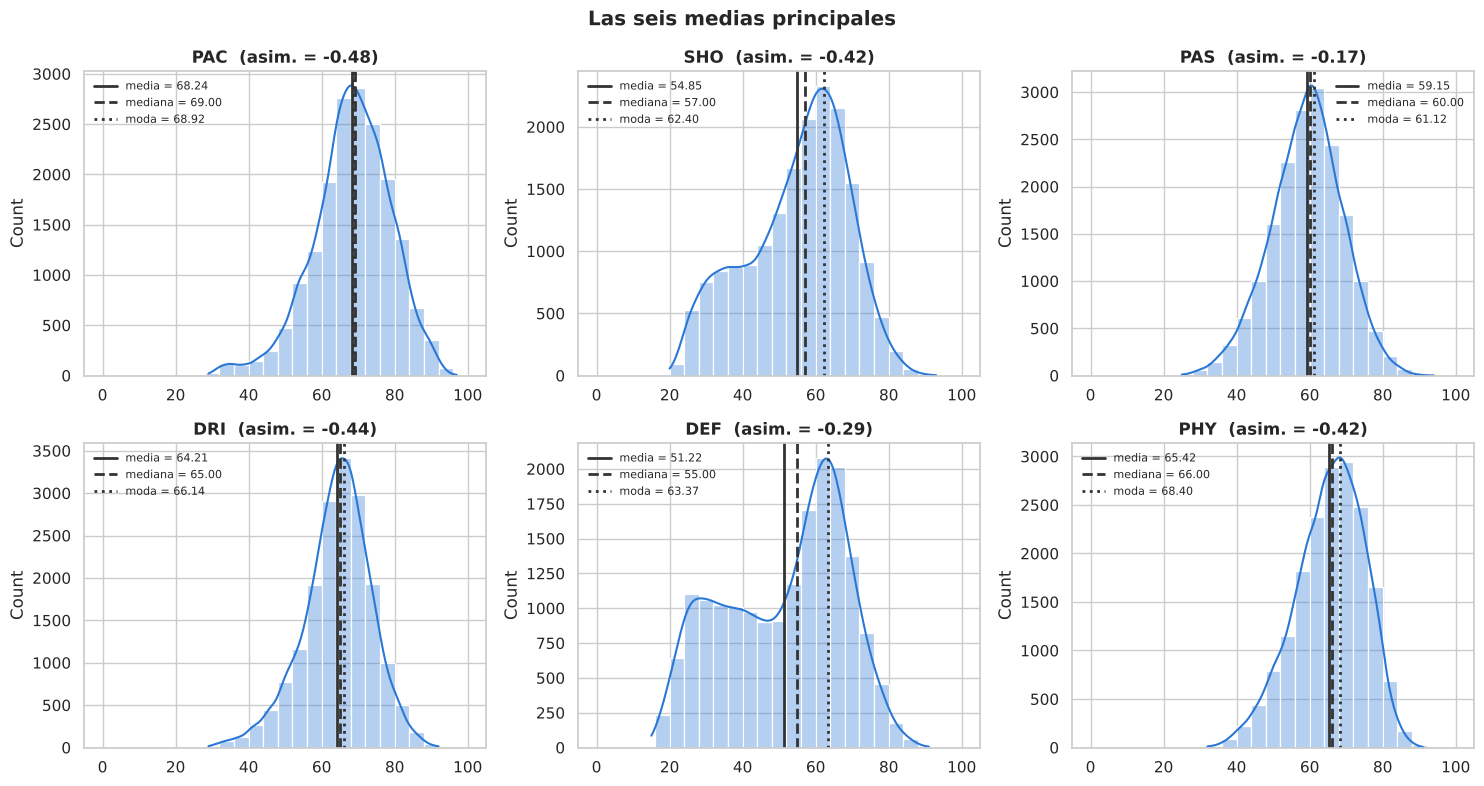

In [26]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, attr in zip(axes.flat, seis):
    histograma_con_centros(df[attr], f"{attr}  (asim. = {df[attr].skew():.2f})", bins=range(0, 101, 4), ax=ax)
    ax.set_xlabel(""); ax.legend(fontsize=8, frameon=False)
plt.suptitle("Las seis medias principales", fontweight="bold")
plt.tight_layout(); plt.show()

🤔 `DEF` (y atributos como `Sliding Tackle` o `Standing Tackle`) tienen **dos jorobas** (distribución bimodal).
¿Por qué? Hipótesis: hay dos "poblaciones" mezcladas, **defensas** y **no defensas**. Lo comprobamos separando por grupo:

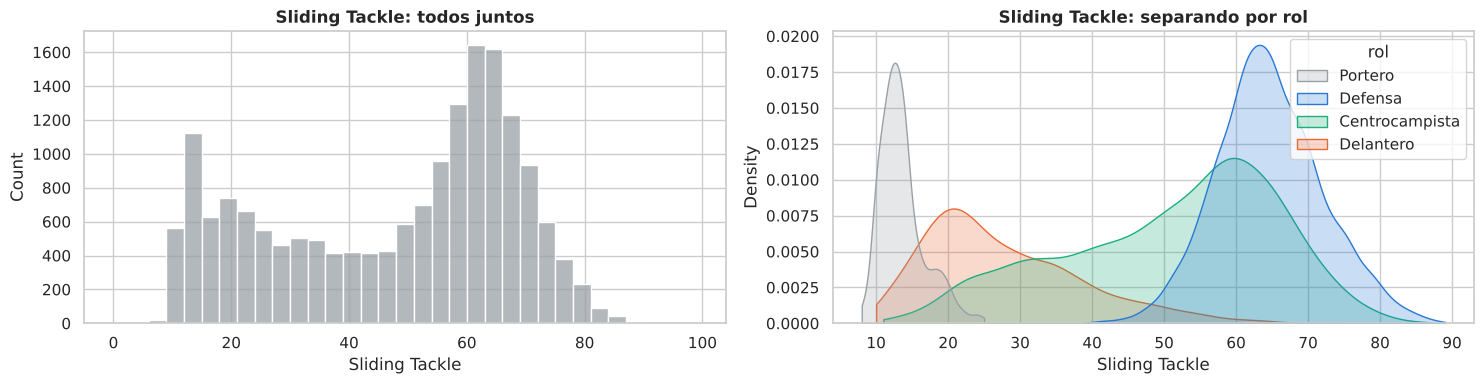

In [27]:
df["rol"] = np.select(
    [df["Position"] == "GK",
     df["Position"].isin(["CB", "LB", "RB", "LWB", "RWB"]),
     df["Position"].isin(["CDM", "CM", "CAM", "LM", "RM"])],
    ["Portero", "Defensa", "Centrocampista"], default="Delantero")
orden_rol = ["Portero", "Defensa", "Centrocampista", "Delantero"]
paleta_rol = dict(zip(orden_rol, ["#9aa0a6", AZUL, VERDE, NARANJA]))

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
sns.histplot(df, x="Sliding Tackle", bins=range(0, 101, 3), ax=axes[0], color="#9aa0a6")
axes[0].set_title("Sliding Tackle: todos juntos")
sns.kdeplot(data=df, x="Sliding Tackle", hue="rol", hue_order=orden_rol, palette=paleta_rol,
            common_norm=True, fill=True, alpha=0.25, ax=axes[1], cut=0)
axes[1].set_title("Sliding Tackle: separando por rol")
plt.tight_layout(); plt.show()

🎯 **Lección:** una distribución bimodal suele avisar de que estamos mezclando grupos distintos.
Y en ese caso la media (que cae en el "valle" entre las dos jorobas) **no representa a nadie**.

### 🕵️ Segundo misterio: ¿los porteros tiran tan bien como los delanteros?

In [28]:
df.groupby("Position")[seis].mean().round(0).loc[["GK", "CB", "ST"]]

,PAC,SHO,PAS,DRI,DEF,PHY
Position,,,,,,
GK,66.000,64.000,63.000,67.000,36.000,64.000
CB,60.000,37.000,51.000,54.000,67.000,72.000
ST,71.000,66.000,55.000,66.000,32.000,67.000


Un portero con `SHO` = 64 de media, casi como un delantero (66), no tiene sentido futbolístico. Lo que pasa es que en las cartas de portero
esas seis columnas guardan **otras medias** (estirada, blocaje, saque, reflejos, velocidad, colocación). Es la misma columna con
**otro significado** según la fila. Por eso, en los análisis de las seis medias **quitamos a los porteros**:

In [29]:
campo = df[df["Position"] != "GK"]
print(f"DEF media con porteros: {df['DEF'].mean():.2f} | sin porteros: {campo['DEF'].mean():.2f}")
print(f"SHO media con porteros: {df['SHO'].mean():.2f} | sin porteros: {campo['SHO'].mean():.2f}")

DEF media con porteros: 51.22 | sin porteros: 53.18
SHO media con porteros: 54.85 | sin porteros: 53.69


### 🚀 Retos de la sesión 1
1. Haz la tabla de frecuencias de `Weak foot` con frecuencias acumuladas. ¿Cuál es su mediana?
2. Compara media, mediana y moda de `Age` con `histograma_con_centros(df['Age'])`. ¿Qué asimetría tiene?
3. ¿Qué atributo (de la lista `atributos`) tiene el **mayor** coeficiente de variación? ¿Y el menor? ¿Por qué crees que es así?
4. Busca otro atributo con dos jorobas, además de `DEF` y `Sliding Tackle`, y explica qué grupos se mezclan.

---
✅ **Fin de la sesión 1.**

---
# 🕐 Sesión 2 de 3 · Atípicos, tipificación y comparación de grupos
**Objetivos:** detectar atípicos (Tukey y z), comparar observaciones con z-scores y percentiles, comparar grupos con `groupby`.  
**Apartados:** 7 a 9 · **Duración orientativa:** 2 horas
> 💡 Si abres el notebook en una sesión nueva, ejecuta antes todas las celdas anteriores: menú *Entorno de ejecución → Ejecutar las celdas anteriores* (Ctrl+F8).

## 7. Datos anómalos

In [30]:
li, ls = limites_tukey(df["OVR"])
print(f"Vallas de Tukey para OVR: [{li:.1f}, {ls:.1f}]")
cracks = df[df["OVR"] > ls]
print(f"{len(cracks)} jugadores son 'atípicos por arriba':")
cracks[["Name", "OVR", "Position", "Age", "Team"]].head(20)

Vallas de Tukey para OVR: [48.5, 84.5]
148 jugadores son 'atípicos por arriba':


,Name,OVR,Position,Age,Team
0,Kylian Mbappé,91,ST,25,Real Madrid
1,Rodri,91,CDM,28,Manchester City
2,Erling Haaland,91,ST,24,Manchester City
3,Jude Bellingham,90,CAM,21,Real Madrid
4,Vini Jr.,90,LW,24,Real Madrid
5,Kevin De Bruyne,90,CM,33,Manchester City
6,Harry Kane,90,ST,31,FC Bayern München
7,Martin Ødegaard,89,CM,25,Arsenal
8,Gianluigi Donnarumma,89,GK,25,Paris SG
9,Alisson,89,GK,31,Liverpool


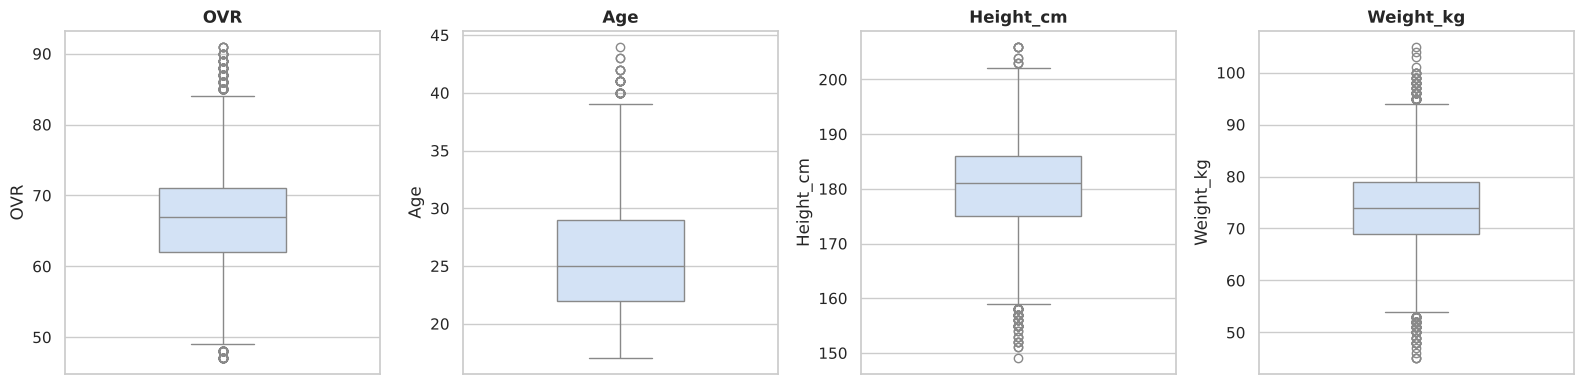

In [31]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, v in zip(axes, ["OVR", "Age", "Height_cm", "Weight_kg"]):
    sns.boxplot(y=df[v], ax=ax, color="#cde2fb", width=0.4)
    ax.set_title(v)
plt.tight_layout(); plt.show()

In [32]:
for v in ["Age", "Height_cm", "Weight_kg"]:
    print(f"\n--- {v}: extremos ---")
    print(pd.concat([df.nsmallest(3, v), df.nlargest(3, v)])[["Name", v, "Position", "Team"]].to_string(index=False))


--- Age: extremos ---
            Name  Age Position            Team
    Lamine Yamal   17       RW    FC Barcelona
     Pau Cubarsí   17       CB    FC Barcelona
     Kendry Páez   17      CAM             IDV
      Joel Pinto   44       GK  Sport Huancayo
Roque Santa Cruz   43       ST        Libertad
      Joe Murphy   43       GK Tranmere Rovers

--- Height_cm: extremos ---
             Name  Height_cm Position             Team
     Kiki Pickett        149      CDM           Bay FC
             Nana        151       RB       Real Betis
   Lorena Navarro        151       CM    Real Sociedad
   Kjell Scherpen        206       GK    SK Sturm Graz
      Isaak Touré        206       CB          Udinese
Denys Tvardovskyi        206       GK Shakhtar Donetsk

--- Weight_kg: extremos ---
               Name  Weight_kg Position             Team
        Elena Julve         45       RW Levante Badalona
Koko Ange N'Guessan         45       RW      UD Tenerife
        Clau Blanco         45    

🤔 **¿Error o crack?** Un atípico no es automáticamente un error. Un portero de 2,06 m es raro pero real;
una jugadora de 1,49 m es atípica entre **todos** los jugadores… pero ¿lo es dentro de su liga?
**Un atípico lo es respecto a un grupo de referencia.** Repetimos la regla de Tukey separando por sexo:

In [33]:
filas = []
for sexo, g in df.groupby("sexo"):
    li, ls = limites_tukey(g["Height_cm"])
    filas.append({"sexo": sexo, "valla_inf": li, "valla_sup": ls,
                  "atipicos_dentro_del_grupo": ((g["Height_cm"] < li) | (g["Height_cm"] > ls)).sum()})
li, ls = limites_tukey(df["Height_cm"])
print(f"Todos juntos: vallas [{li:.1f}, {ls:.1f}] -> {((df['Height_cm'] < li) | (df['Height_cm'] > ls)).sum()} atípicos")
pd.DataFrame(filas).set_index("sexo")

Todos juntos: vallas [158.5, 202.5] -> 75 atípicos


,valla_inf,valla_sup,atipicos_dentro_del_grupo
sexo,,,
Femenino,153.000,185.000,12
Masculino,162.000,202.000,21


**Antes de borrar un dato, hay que entenderlo.**

## 8. Tipificación (z-scores): ¿quién es el más excepcional?
$$ z = \frac{x - \bar x}{s} $$
Es "a cuántas desviaciones típicas de la media" está un jugador. Así comparamos atributos con medias y dispersiones distintas.

In [34]:
Z = (campo[seis] - campo[seis].mean()) / campo[seis].std()   # sin porteros
extremos = pd.DataFrame({
    "jugador": [campo.loc[Z[a].idxmax(), "Name"] for a in seis],
    "valor": [campo.loc[Z[a].idxmax(), a] for a in seis],
    "z_max": [Z[a].max() for a in seis],
}, index=seis)
extremos

,jugador,valor,z_max
PAC,Kylian Mbappé,97,2.617
SHO,Harry Kane,93,2.793
PAS,Kevin De Bruyne,94,3.546
DRI,Kylian Mbappé,92,2.967
DEF,Wendie Renard,91,2.354
PHY,Viktor Gyökeres,91,2.651


🤔 Un 97 en ritmo y un 90 en defensa: ¿cuál es **más** excepcional? El que tenga mayor z.

In [35]:
def ficha_jugador(nombre):
    """Valor, z y percentil de un jugador en las seis medias y en OVR."""
    fila = df.loc[df["Name"] == nombre]
    if fila.empty:
        print("No encontrado. Prueba con:", df["Name"].head(10).tolist()); return
    fila = fila.iloc[0]
    out = []
    for v in ["OVR"] + seis + ["Age", "Height_cm"]:
        out.append({"variable": v, "valor": fila[v],
                    "z": (fila[v] - df[v].mean()) / df[v].std(),
                    "percentil": stats.percentileofscore(df[v], fila[v])})
    print(f"{fila['Name']} · {fila['Position']} · {fila['Team']}")
    return pd.DataFrame(out).set_index("variable")

ficha_jugador(df.loc[df["OVR"].idxmax(), "Name"])

Kylian Mbappé · ST · Real Madrid


,valor,z,percentil
variable,,,
OVR,91,3.442,99.992
PAC,97,2.717,100.000
SHO,90,2.537,99.986
PAS,80,2.122,98.627
DRI,92,2.970,99.992
DEF,36,-0.924,23.699
PHY,78,1.329,92.087
Age,25,-0.160,48.015
Height_cm,182,0.167,54.226


👉 Probad con vuestro jugador favorito: `ficha_jugador("Pedri")`, `ficha_jugador("Lamine Yamal")`…

## 9. 🏆 Comparación por grupos con `groupby`
### 9.1 Por posición

In [36]:
por_pos = (df.groupby("Position")["OVR"]
             .agg(n="size", media="mean", mediana="median", desv="std",
                  Q1=lambda s: s.quantile(.25), Q3=lambda s: s.quantile(.75), maximo="max")
             .sort_values("mediana", ascending=False))
por_pos.style.format("{:.2f}").background_gradient(subset=["media"], cmap="Blues")

,n,media,mediana,desv,Q1,Q3,maximo
Position,,,,,,,
CAM,1024.00,67.11,67.00,7.38,62.00,72.00,90.00
CB,3185.00,67.16,67.00,6.68,63.00,71.00,89.00
CDM,1447.00,67.60,67.00,6.79,63.00,72.00,91.00
LW,383.00,67.66,67.00,7.92,62.00,72.50,90.00
ST,2425.00,66.87,67.00,7.05,62.00,71.00,91.00
LM,1035.00,67.05,67.00,6.36,63.00,71.00,88.00
RW,402.00,67.27,67.00,8.20,62.00,72.00,90.00
RM,961.00,67.15,67.00,6.44,63.00,71.00,85.00
CM,2139.00,66.63,66.00,7.39,62.00,71.50,91.00


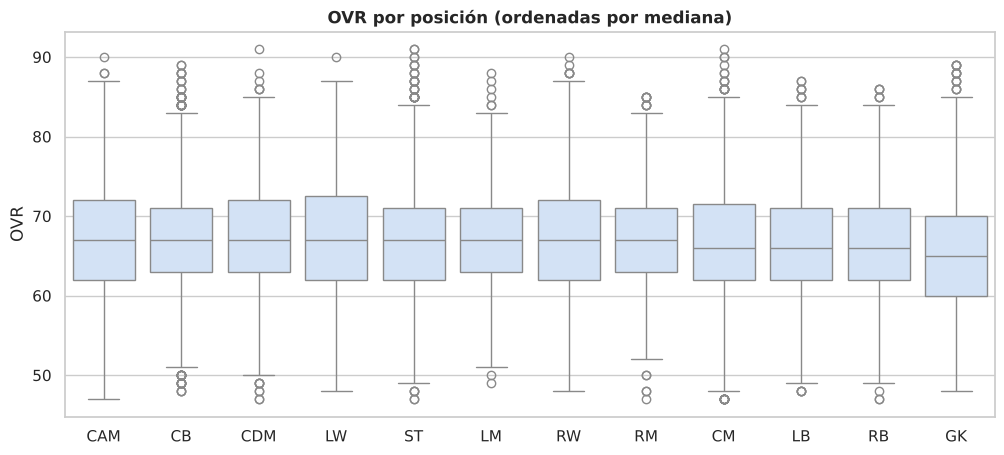

In [37]:
orden = por_pos.index
fig, ax = plt.subplots(figsize=(12, 5))
sns.boxplot(data=df, x="Position", y="OVR", order=orden, color="#cde2fb", ax=ax)
ax.set_title("OVR por posición (ordenadas por mediana)"); ax.set_xlabel("")
plt.show()

### Perfil de cada posición (medias de las seis medias)

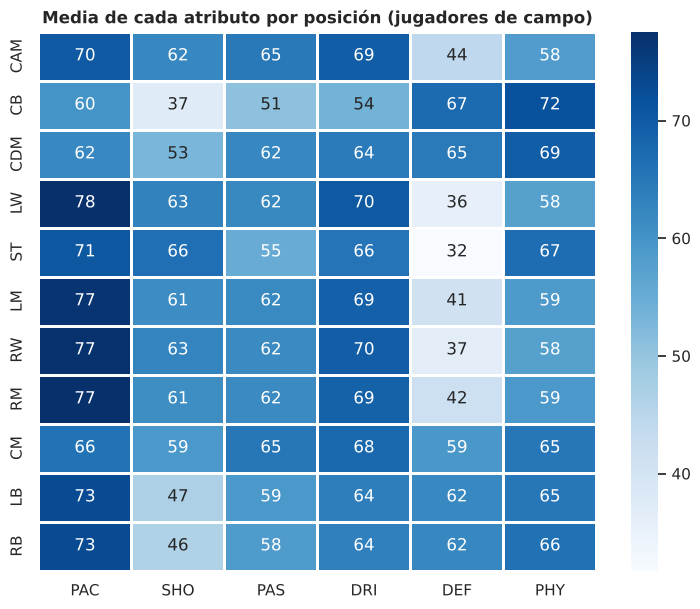

In [38]:
perfil = campo.groupby("Position")[seis].mean().loc[[p for p in orden if p != "GK"]]
plt.figure(figsize=(9, 7))
sns.heatmap(perfil, annot=True, fmt=".0f", cmap="Blues", linewidths=2, linecolor="white")
plt.title("Media de cada atributo por posición (jugadores de campo)"); plt.ylabel(""); plt.show()

### 9.2 Por liga: ¿la mejor… y la más igualada?

In [39]:
por_liga = (df.groupby("League")["OVR"]
              .agg(n="size", media="mean", mediana="median", desv="std",
                   IQR=lambda s: s.quantile(.75) - s.quantile(.25),
                   top=lambda s: (s >= 85).sum())
              .assign(CV=lambda t: 100 * t["desv"] / t["media"])
              .query("n >= 100")
              .sort_values("media", ascending=False))
por_liga.head(15).style.format("{:.2f}").background_gradient(subset=["media"], cmap="Blues").background_gradient(subset=["CV"], cmap="Oranges")

,n,media,mediana,desv,IQR,top,CV
League,,,,,,,
Premier League,597.00,74.27,76.00,7.44,8.00,31.00,10.02
Barclays WSL,255.00,74.14,75.00,7.42,9.00,18.00,10.01
Arkema PL,198.00,73.96,73.00,6.46,8.00,13.00,8.74
LALIGA EA SPORTS,529.00,73.87,74.00,6.29,8.00,23.00,8.52
NWSL,347.00,73.79,74.00,5.92,9.00,8.00,8.02
Serie A Enilive,537.00,73.27,73.00,5.79,7.00,12.00,7.90
Bundesliga,485.00,72.76,73.00,6.19,7.00,14.00,8.51
GPFBL,289.00,72.65,72.00,5.83,8.00,6.00,8.02
Liga F,327.00,72.57,73.00,6.79,8.00,10.00,9.36


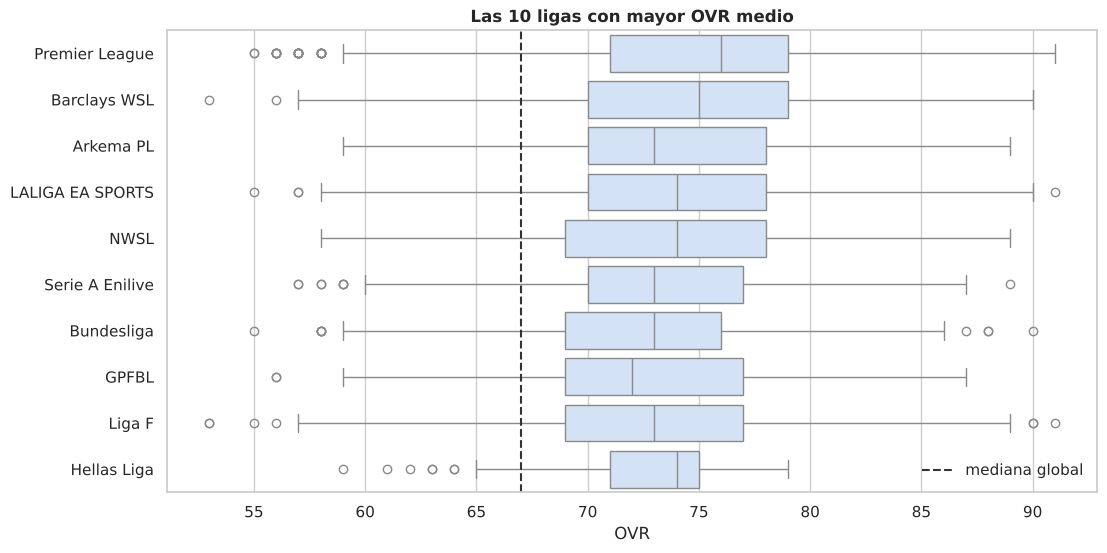

In [40]:
top10 = por_liga.index[:10]
fig, ax = plt.subplots(figsize=(12, 6))
sns.boxplot(data=df[df["League"].isin(top10)], y="League", x="OVR", order=top10, color="#cde2fb", ax=ax)
ax.axvline(df["OVR"].median(), color="#333333", ls="--", label="mediana global")
ax.set_title("Las 10 ligas con mayor OVR medio"); ax.set_ylabel(""); ax.legend(frameon=False)
plt.show()

🤔 1. ¿Qué liga tiene **menor CV**? ¿Significa que es la más "igualada"?
2. ¿Hay ligas donde la media y la mediana se separan mucho? ¿Qué te dice eso de sus estrellas?

### 9.3 La trampa de los grupos pequeños: ranking de nacionalidades

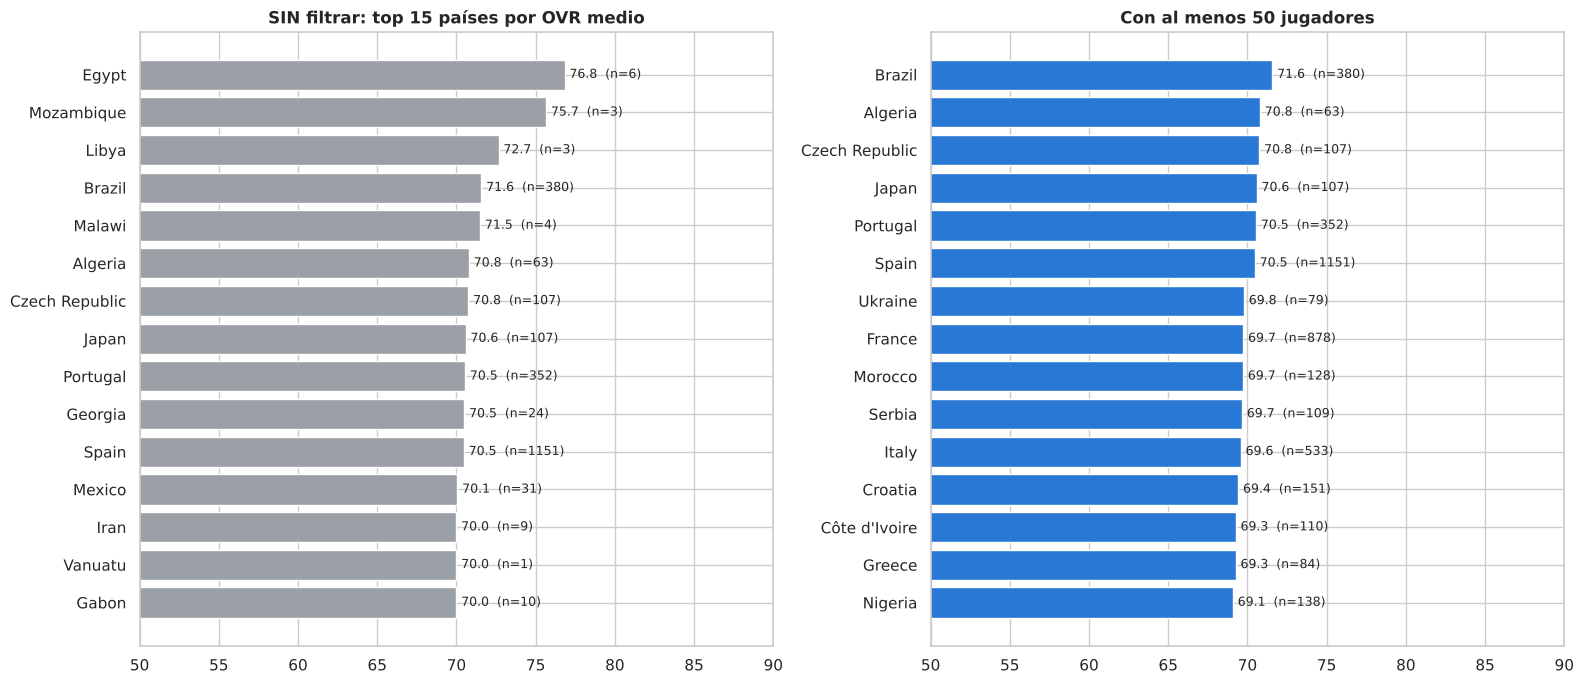

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
sin_filtro = df.groupby("Nation")["OVR"].agg(["mean", "size"]).sort_values("mean", ascending=False).head(15)
axes[0].barh(sin_filtro.index[::-1], sin_filtro["mean"][::-1], color="#9aa0a6")
for i, (m, n) in enumerate(zip(sin_filtro["mean"][::-1], sin_filtro["size"][::-1])):
    axes[0].text(m + 0.3, i, f"{m:.1f}  (n={n})", va="center", fontsize=9)
axes[0].set_title("SIN filtrar: top 15 países por OVR medio"); axes[0].set_xlim(50, 90)

con_filtro = df.groupby("Nation")["OVR"].agg(["mean", "size"]).query("size >= 50").sort_values("mean", ascending=False).head(15)
axes[1].barh(con_filtro.index[::-1], con_filtro["mean"][::-1], color=AZUL)
for i, (m, n) in enumerate(zip(con_filtro["mean"][::-1], con_filtro["size"][::-1])):
    axes[1].text(m + 0.3, i, f"{m:.1f}  (n={n})", va="center", fontsize=9)
axes[1].set_title("Con al menos 50 jugadores"); axes[1].set_xlim(50, 90)
plt.tight_layout(); plt.show()

🎯 **Lección:** un país con 1 jugador muy bueno "gana" el ranking de medias. Una media calculada con **n = 1** no describe a ningún grupo.
Siempre que hagáis un `groupby`, **mirad también el tamaño de cada grupo** (`size`).

### 9.4 Por equipo: los mejores… y los más desiguales

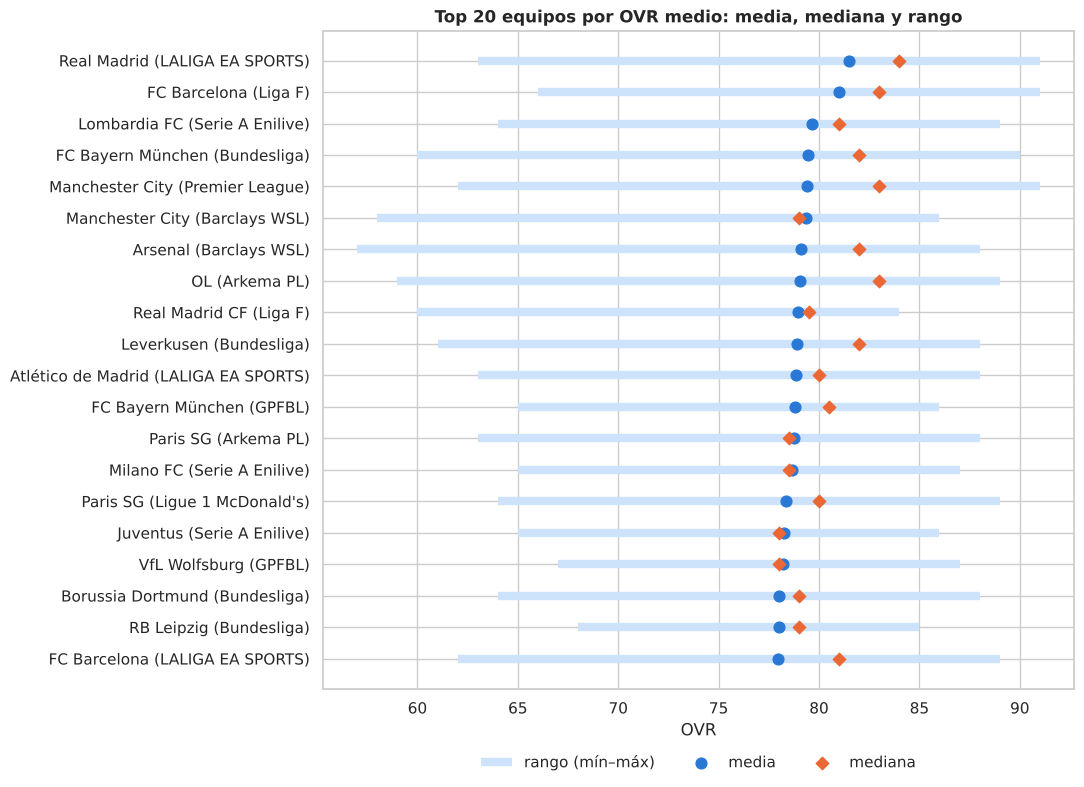

In [42]:
por_equipo = (df.groupby("equipo")["OVR"]
                .agg(n="size", media="mean", mediana="median", desv="std", maximo="max", minimo="min",
                     estrellas=lambda s: (s >= 85).sum())
                .query("n >= 18"))
top = por_equipo.sort_values("media", ascending=False).head(20)
fig, ax = plt.subplots(figsize=(11, 8))
eq = top.index[::-1]
ax.hlines(eq, top["minimo"][::-1], top["maximo"][::-1], color="#cde2fb", lw=6, label="rango (mín–máx)")
ax.scatter(top["media"][::-1], eq, color=AZUL, zorder=3, s=60, label="media")
ax.scatter(top["mediana"][::-1], eq, color=NARANJA, zorder=3, s=40, marker="D", label="mediana")
ax.set_title("Top 20 equipos por OVR medio: media, mediana y rango"); ax.set_xlabel("OVR")
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.08))
plt.tight_layout(); plt.show()

In [43]:
print("Los 10 equipos más DESIGUALES (mayor desviación típica de OVR):")
por_equipo.sort_values("desv", ascending=False).head(10)

Los 10 equipos más DESIGUALES (mayor desviación típica de OVR):


,n,media,mediana,desv,maximo,minimo,estrellas
equipo,,,,,,,
Al Ahli (ROSHN Saudi League),31,64.387,63.000,10.726,85,50,1
Liverpool (Premier League),33,75.364,78.000,10.541,89,56,7
Al Ittihad (ROSHN Saudi League),28,68.571,67.000,9.724,86,53,2
Arsenal (Premier League),28,77.750,81.500,9.509,89,58,6
Manchester City (Premier League),28,79.393,83.000,9.473,91,62,9
Man Utd (Premier League),32,74.594,78.000,9.435,87,56,1
Al Shabab (ROSHN Saudi League),22,65.909,63.000,9.421,83,50,0
Al Hilal (ROSHN Saudi League),23,73.609,73.000,9.413,87,60,3
Al Nassr (ROSHN Saudi League),28,70.107,68.500,9.390,86,56,1


### 9.5 ¿A qué edad se alcanza el pico?

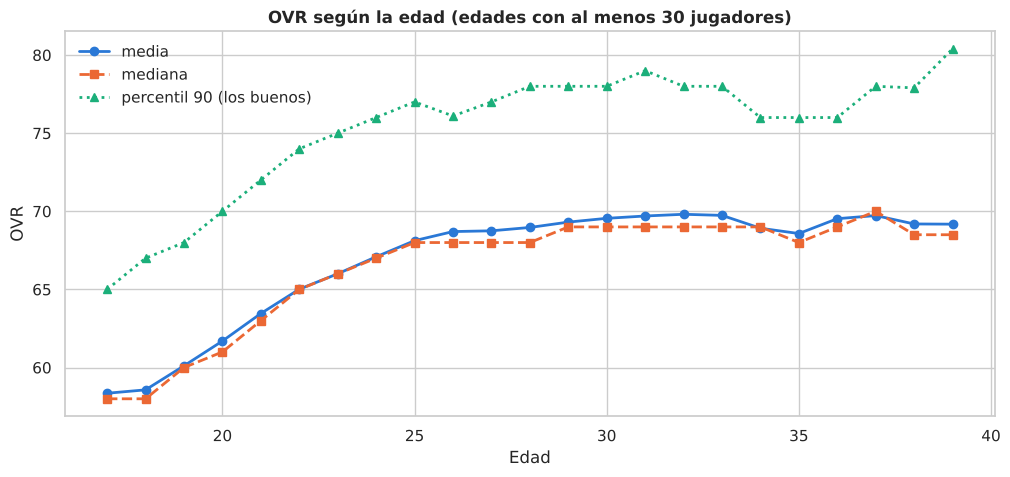

Edad con mayor OVR medio: 32


In [44]:
por_edad = df.groupby("Age")["OVR"].agg(n="size", media="mean", mediana="median",
                                         p90=lambda s: s.quantile(.9)).query("n >= 30")
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(por_edad.index, por_edad["media"], marker="o", color=AZUL, lw=2, label="media")
ax.plot(por_edad.index, por_edad["mediana"], marker="s", color=NARANJA, lw=2, ls="--", label="mediana")
ax.plot(por_edad.index, por_edad["p90"], marker="^", color=VERDE, lw=2, ls=":", label="percentil 90 (los buenos)")
ax.set_xlabel("Edad"); ax.set_ylabel("OVR"); ax.set_title("OVR según la edad (edades con al menos 30 jugadores)")
ax.legend(frameon=False); plt.show()
print("Edad con mayor OVR medio:", por_edad["media"].idxmax())

🤔 ¿La curva baja a partir de cierta edad porque los jugadores **empeoran**… o porque solo los muy buenos **siguen jugando**?
(Esto se llama *sesgo de supervivencia*.)

### 9.6 Dos cualitativas: ¿en qué posiciones juegan los zurdos?

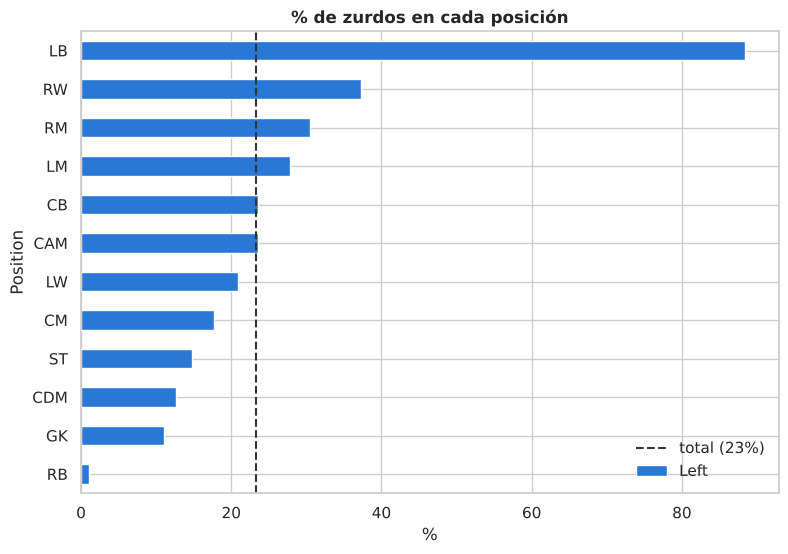

In [45]:
tc = pd.crosstab(df["Position"], df["Preferred foot"], normalize="index").mul(100).sort_values("Left")
ax = tc["Left"].plot.barh(color=AZUL, figsize=(9, 6))
ax.axvline(zurdos, color="#333333", ls="--", label=f"total ({zurdos:.0f}%)")
ax.set_title("% de zurdos en cada posición"); ax.set_xlabel("%"); ax.legend(frameon=False)
plt.show()

### 🚀 Retos de la sesión 2
1. Repite la tabla de ligas usando la **mediana** para ordenar. ¿Cambia el top 5?
2. ¿Qué equipo tiene más jugadores **atípicos por arriba** (según Tukey) en su plantilla?
3. Construye el **"once ideal"**: el mejor jugador (mayor OVR) de cada posición con `groupby("Position")["OVR"].idxmax()`.
4. ¿Qué equipo **femenino** tiene el OVR medio más alto? ¿Y la liga femenina más igualada?
5. ¿Qué nacionalidad (con n ≥ 50) es la más **homogénea** en OVR? ¿Y la más desigual?
6. Elige tú una pregunta y respóndela con un `groupby` y un gráfico. ¡La mejor se enseña en clase!

---
✅ **Fin de la sesión 2.**

---
# 🕐 Sesión 3 de 3 · Dos variables: correlación y regresión
**Objetivos:** covarianza y correlación, recta de regresión, modelos potencial y exponencial, residuos y predicción.  
**Apartados:** 10 a 12 · **Duración orientativa:** 2 horas
> 💡 Si abres el notebook en una sesión nueva, ejecuta antes todas las celdas anteriores: menú *Entorno de ejecución → Ejecutar las celdas anteriores* (Ctrl+F8).

## 10. Dos variables cuantitativas: covarianza y correlación

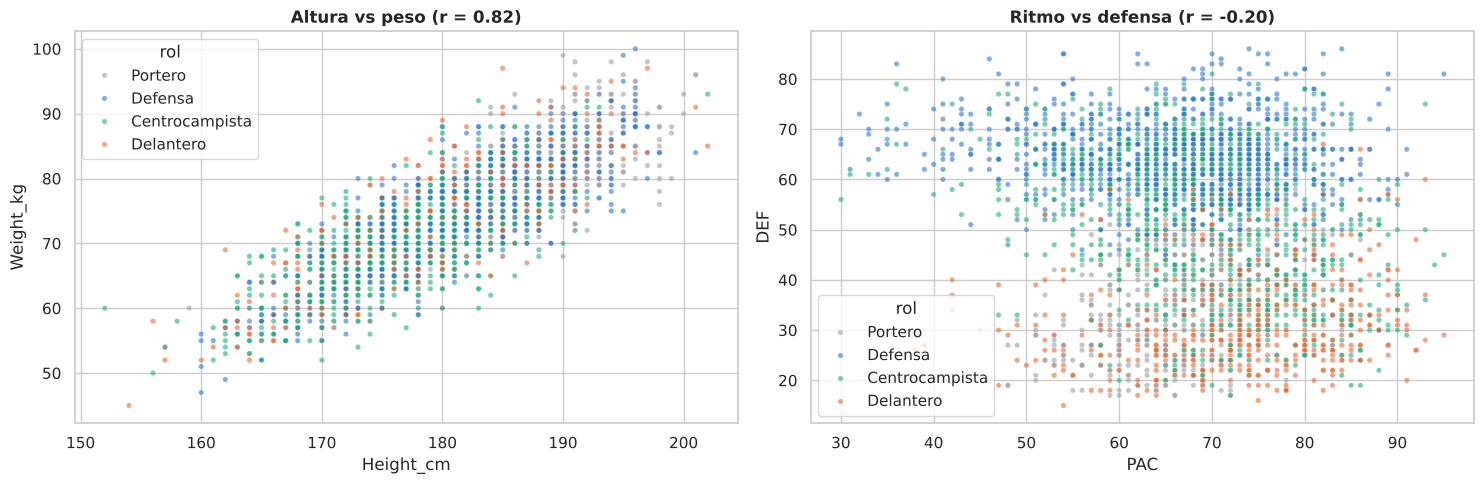

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.scatterplot(data=df.sample(min(3000, len(df)), random_state=1), x="Height_cm", y="Weight_kg",
                hue="rol", hue_order=orden_rol, palette=paleta_rol, s=15, alpha=0.6, ax=axes[0])
axes[0].set_title(f"Altura vs peso (r = {df['Height_cm'].corr(df['Weight_kg']):.2f})")
sns.scatterplot(data=df.sample(min(3000, len(df)), random_state=1), x="PAC", y="DEF",
                hue="rol", hue_order=orden_rol, palette=paleta_rol, s=15, alpha=0.6, ax=axes[1])
axes[1].set_title(f"Ritmo vs defensa (r = {df['PAC'].corr(df['DEF']):.2f})")
plt.tight_layout(); plt.show()

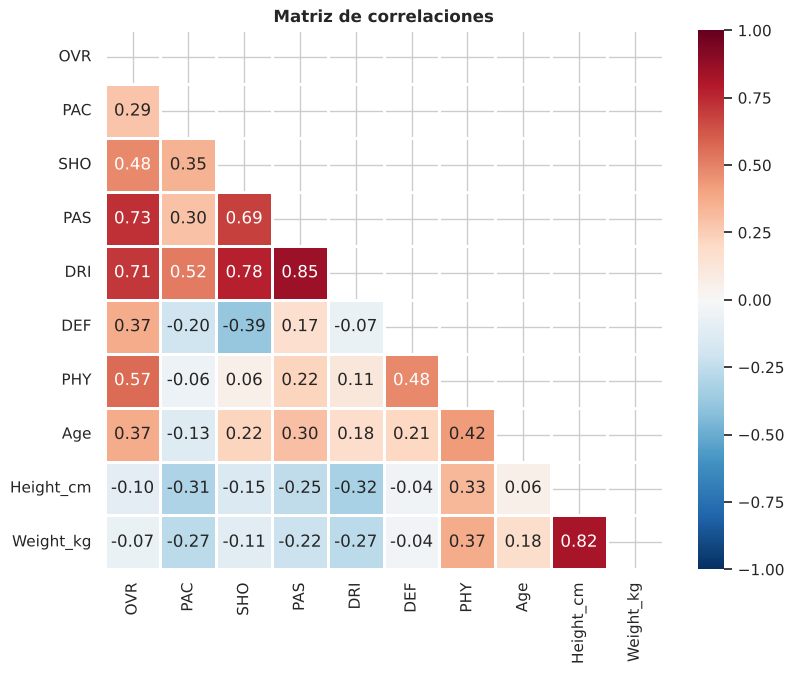

In [47]:
corr = df[["OVR"] + seis + ["Age", "Height_cm", "Weight_kg"]].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(9, 7))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, linewidths=2, linecolor="white")
plt.title("Matriz de correlaciones"); plt.show()

## 11. 📈 Regresión: ¿podemos predecir el peso a partir de la altura?
Vamos a ajustar tres modelos por **mínimos cuadrados** para explicar el peso ($y$) a partir de la altura ($x$):

| Modelo | Ecuación | Cómo se ajusta |
|---|---|---|
| Lineal | $y = a + b\,x$ | directamente |
| Potencial | $y = a\,x^{b}$ | tomando logaritmos: $\ln y = \ln a + b\,\ln x$ |
| Exponencial | $y = a\,e^{b x}$ | tomando logaritmos: $\ln y = \ln a + b\,x$ |

### 11.1 La recta de regresión, paso a paso
$$ b = \frac{S_{xy}}{S_x^2}, \qquad a = \bar y - b\,\bar x, \qquad R^2 = r^2 = \left(\frac{S_{xy}}{S_x S_y}\right)^2 $$

In [48]:
x, y = df["Height_cm"], df["Weight_kg"]
media_x, media_y = x.mean(), y.mean()
Sx2 = ((x - media_x) ** 2).mean()                  # varianza de x (dividiendo entre n)
Sy2 = ((y - media_y) ** 2).mean()
Sxy = ((x - media_x) * (y - media_y)).mean()        # covarianza
b = Sxy / Sx2
a = media_y - b * media_x
r = Sxy / np.sqrt(Sx2 * Sy2)
print(f"media altura = {media_x:.2f} cm   media peso = {media_y:.2f} kg")
print(f"S_x^2 = {Sx2:.3f}   S_y^2 = {Sy2:.3f}   S_xy = {Sxy:.3f}")
print(f"b = S_xy / S_x^2 = {b:.4f} kg por cada cm")
print(f"a = media_y - b·media_x = {a:.3f}")
print(f"Recta de y sobre x:  peso = {a:.2f} + {b:.4f}·altura")
print(f"r = {r:.4f}   ->   R^2 = {r**2:.4f}  (la altura explica el {100*r**2:.1f} % de la variabilidad del peso)")

media altura = 180.71 cm   media peso = 73.95 kg
S_x^2 = 59.801   S_y^2 = 64.382   S_xy = 50.959
b = S_xy / S_x^2 = 0.8521 kg por cada cm
a = media_y - b·media_x = -80.037
Recta de y sobre x:  peso = -80.04 + 0.8521·altura
r = 0.8213   ->   R^2 = 0.6745  (la altura explica el 67.4 % de la variabilidad del peso)


🤔 **Interpretación:** por cada centímetro más de altura, el peso aumenta de media unos `b` kg. ¿Y qué significa `a`?
(Sería el peso de un jugador de 0 cm… **no tiene sentido**: fuera del rango de los datos la recta no vale.)

### 11.2 Las dos rectas de regresión
La recta de **y sobre x** (predecir el peso con la altura) **no es la misma** que la de **x sobre y** (predecir la altura con el peso).
Las dos se cortan en el **centro de gravedad** $(\bar x, \bar y)$, y cuanto más se parecen, mayor es $|r|$.

Recta de x sobre y:  altura = 122.17 + 0.7915·peso
Comprobación: b · b' = 0.6745 = r^2 = 0.6745


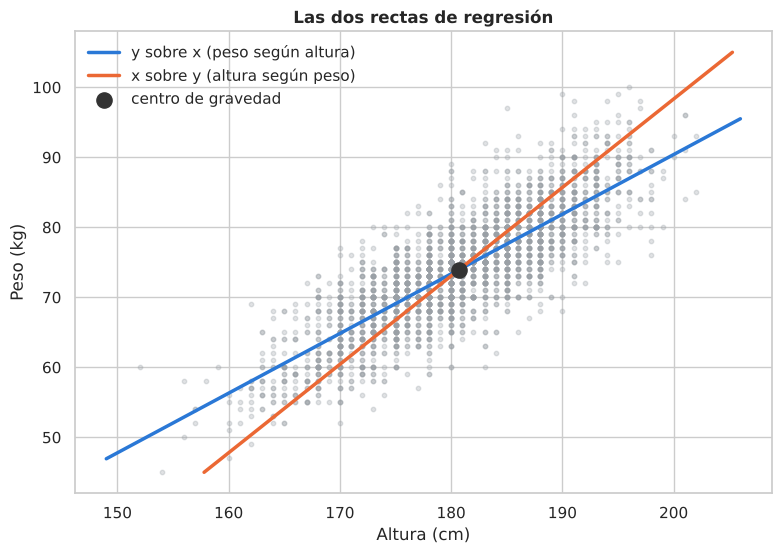

In [49]:
a_xy, b_xy = recta_minimos_cuadrados(y, x)          # altura = a' + b'·peso
print(f"Recta de x sobre y:  altura = {a_xy:.2f} + {b_xy:.4f}·peso")
print(f"Comprobación: b · b' = {b * b_xy:.4f} = r^2 = {r**2:.4f}")

fig, ax = plt.subplots(figsize=(9, 6))
m = df.sample(3000, random_state=1)
ax.scatter(m["Height_cm"], m["Weight_kg"], s=10, alpha=0.3, color="#9aa0a6")
xs = np.linspace(x.min(), x.max(), 100)
ax.plot(xs, a + b * xs, color=AZUL, lw=2.5, label="y sobre x (peso según altura)")
ys = np.linspace(y.min(), y.max(), 100)
ax.plot(a_xy + b_xy * ys, ys, color=NARANJA, lw=2.5, label="x sobre y (altura según peso)")
ax.scatter([media_x], [media_y], s=120, color="#333333", zorder=5, label="centro de gravedad")
ax.set_xlabel("Altura (cm)"); ax.set_ylabel("Peso (kg)"); ax.set_title("Las dos rectas de regresión")
ax.legend(frameon=False); plt.show()

### 11.3 Modelos potencial y exponencial: linealizar con logaritmos
Si $y = a\,x^b$, entonces $\ln y = \ln a + b \ln x$: **en escala log-log los puntos deberían quedar en una recta**.
Si $y = a\,e^{bx}$, entonces $\ln y = \ln a + b\,x$: **en escala semilogarítmica** deberían quedar en una recta.
Así que ajustar estos modelos es simplemente ajustar una recta… a los datos transformados.

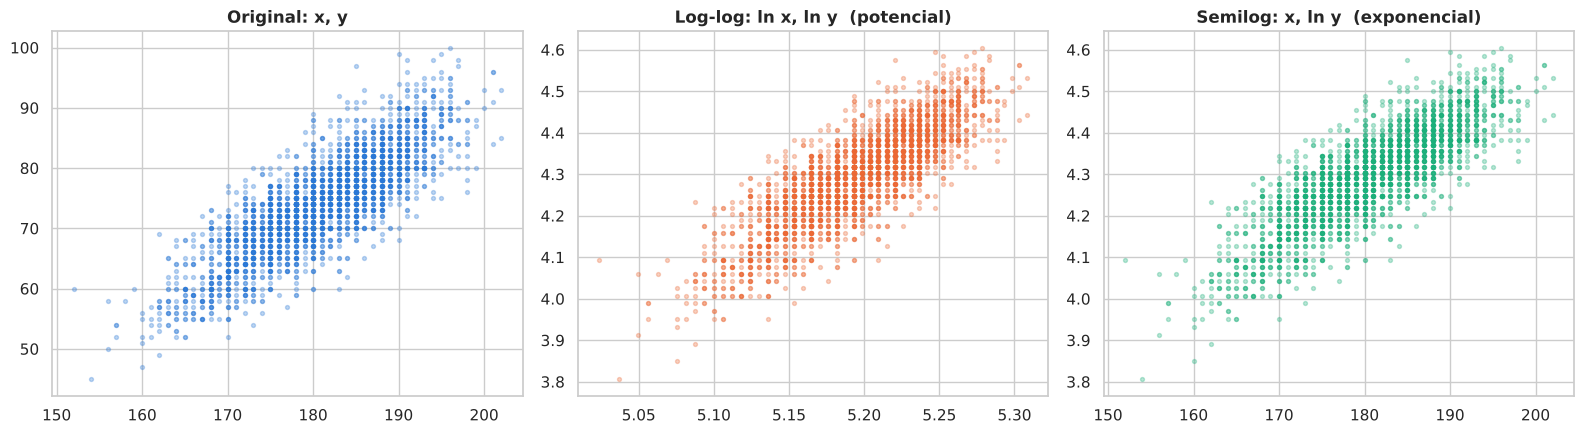

In [50]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].scatter(m["Height_cm"], m["Weight_kg"], s=8, alpha=0.3, color=AZUL); axes[0].set_title("Original: x, y")
axes[1].scatter(np.log(m["Height_cm"]), np.log(m["Weight_kg"]), s=8, alpha=0.3, color=NARANJA); axes[1].set_title("Log-log: ln x, ln y  (potencial)")
axes[2].scatter(m["Height_cm"], np.log(m["Weight_kg"]), s=8, alpha=0.3, color=VERDE); axes[2].set_title("Semilog: x, ln y  (exponencial)")
plt.tight_layout(); plt.show()

In [51]:
tabla_reg, modelos = regresiones(df["Height_cm"], df["Weight_kg"])
tabla_reg

,ecuación,a,b,R2 (escala del ajuste),R2 (escala original)
modelo,,,,,
lineal,y = -80.04 + 0.8521·x,-80.037,0.852,0.674,0.674
potencial,y = 0.001165·x^2.127,0.001165,2.127,0.683,0.672
exponencial,y = 8.663·e^(0.01183·x),8.663,0.012,0.679,0.668


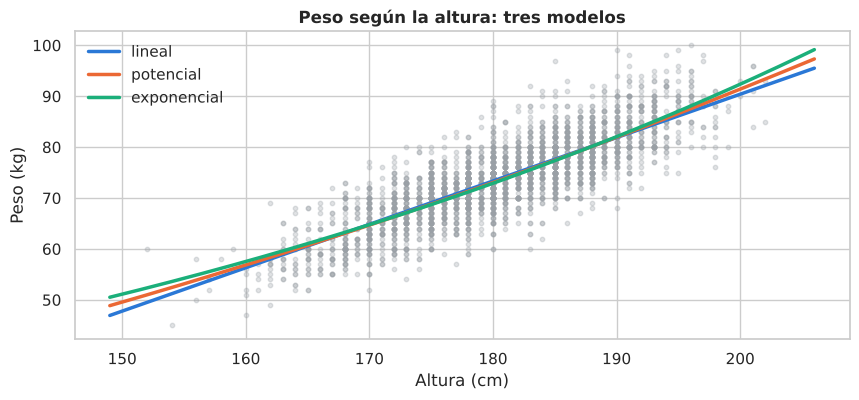

In [52]:
dibujar_regresiones(df["Height_cm"], df["Weight_kg"], modelos,
                    xlabel="Altura (cm)", ylabel="Peso (kg)", titulo="Peso según la altura: tres modelos")
plt.show()

🎯 **¡El exponente del modelo potencial sale cerca de 2!** El **índice de masa corporal** (IMC = peso / altura²) da por hecho que
el peso crece con el **cuadrado** de la altura. Los datos dicen algo parecido. (Si el cuerpo creciera igual en las tres dimensiones,
el exponente sería 3.)

🤔 Los tres modelos tienen un $R^2$ casi idéntico. En el rango de alturas de los futbolistas (150–206 cm) las tres curvas son
prácticamente rectas: **cuando los datos cubren un rango estrecho, la forma del modelo importa poco**.

### 11.4 Residuos: ¿qué queda sin explicar?
Residuo $e_i = y_i - \hat y_i$. Si el modelo es bueno, los residuos no deberían mostrar ningún patrón.

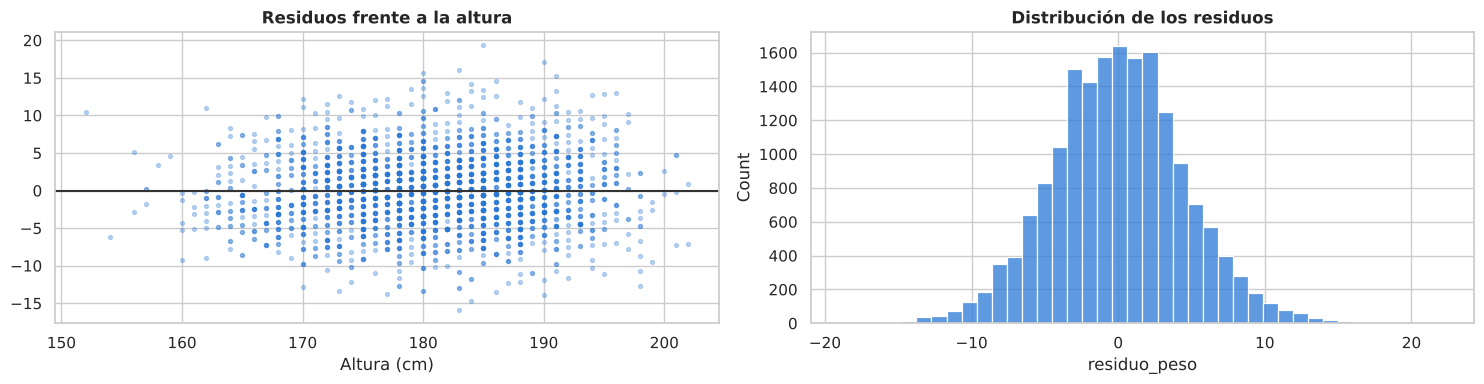

Media de los residuos: 8.00e-15 (siempre 0 en mínimos cuadrados)
Varianza residual: 20.957 = S_y^2·(1 - R^2) = 20.957

Los 5 jugadores más 'pesados para su altura':
         Name  Height_cm  Weight_kg  residuo_peso Position
  Ramón Ábila        177         93        22.208       ST
   Evan Louro        191        104        21.278       GK
   Daryl Dike        188        100        19.834       ST
 Kevin Carlos        186         98        19.539       ST
Andrés Chávez        185         97        19.391       ST


In [53]:
df["residuo_peso"] = df["Weight_kg"] - modelos["lineal"](df["Height_cm"])
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
mm = df.sample(3000, random_state=1)
axes[0].scatter(mm["Height_cm"], mm["residuo_peso"], s=8, alpha=0.3, color=AZUL)
axes[0].axhline(0, color="#333333"); axes[0].set_title("Residuos frente a la altura"); axes[0].set_xlabel("Altura (cm)")
sns.histplot(df["residuo_peso"], bins=40, ax=axes[1], color=AZUL); axes[1].set_title("Distribución de los residuos")
plt.tight_layout(); plt.show()
print(f"Media de los residuos: {df['residuo_peso'].mean():.2e} (siempre 0 en mínimos cuadrados)")
print(f"Varianza residual: {df['residuo_peso'].var(ddof=0):.3f} = S_y^2·(1 - R^2) = {Sy2 * (1 - r**2):.3f}")
print("\nLos 5 jugadores más 'pesados para su altura':")
print(df.nlargest(5, "residuo_peso")[["Name", "Height_cm", "Weight_kg", "residuo_peso", "Position"]].to_string(index=False))

### 11.5 Predecir (con cuidado)

In [54]:
for altura in [170, 190, 230]:
    print(f"Altura {altura} cm -> lineal: {modelos['lineal'](altura):.1f} kg | "
          f"potencial: {modelos['potencial'](altura):.1f} kg | exponencial: {modelos['exponencial'](altura):.1f} kg")

Altura 170 cm -> lineal: 64.8 kg | potencial: 64.7 kg | exponencial: 64.8 kg
Altura 190 cm -> lineal: 81.9 kg | potencial: 81.9 kg | exponencial: 82.0 kg
Altura 230 cm -> lineal: 116.0 kg | potencial: 123.0 kg | exponencial: 131.7 kg


⚠️ Para 230 cm los modelos ya no coinciden: estamos **extrapolando** fuera del rango observado (149–206 cm).
Ningún modelo garantiza nada fuera de los datos con los que se ajustó.

## 12. ¿Regla empírica o Chebyshev?

In [55]:
m, s = df["OVR"].mean(), df["OVR"].std()
pd.DataFrame({
    "observado_%": [100 * df["OVR"].between(m - k*s, m + k*s).mean() for k in (1, 2, 3)],
    "si_fuera_normal_%": [68.27, 95.45, 99.73],
    "Chebyshev_minimo_%": [0, 75, 88.9],
}, index=pd.Index([1, 2, 3], name="k (desviaciones)"))

,observado_%,si_fuera_normal_%,Chebyshev_minimo_%
k (desviaciones),,,
1,69.865,68.270,0.000
2,94.289,95.450,75.000
3,99.758,99.730,88.900


### 🚀 Retos de la sesión 3
1. Repite la regresión potencial peso ~ altura **solo con hombres** y **solo con mujeres**. ¿Sale el mismo exponente que con todos juntos? ¿Por qué?
2. Ajusta los tres modelos para `Sprint Speed` frente a `Acceleration`. ¿Cuál gana?
3. ¿Qué pareja de las seis medias (`PAC`…`PHY`) tiene la correlación más alta en los jugadores de campo? Calcula su recta de regresión e interpreta la pendiente.
4. Calcula las dos rectas de regresión de `OVR` y `Reactions`. ¿Cuánto vale el producto de sus pendientes? ¿Por qué?

---
🏁 **Fin del notebook.**